# DASCM 2026 — Project Part 1
## Port Logistics Dispatching — Exploratory Data Analysis (Classification)

**Course:** Data Analytics in Supply Chain Management  
**Semester:** Fall 2026  
**Dataset:** Port Logistics Dispatching  
**Task:** Exploratory Data Analysis and brainstorming for the six-class target `Recommended_Dispatch_Action`

### Scenario
A port-logistics control tower must respond to changing operating conditions such as traffic congestion, terminal incidents, slot risk, driver-hour constraints, weather, and vehicle technical warnings. The dispatcher must quickly decide what action to take next.

### Analytical task
The dataset is designed to support prediction of:

- `PROCEED_AS_PLANNED`
- `WAIT_AND_MONITOR`
- `RESCHEDULE_SLOT`
- `REROUTE`
- `REASSIGN_VEHICLE`
- `PRIORITY_RECOVERY`

This notebook focuses on **Part 1 EDA only**. It does not train a final classification model. The objective is to understand the dataset, variables, missingness, distributions, outliers, class structure, relationships, and operational hypotheses that can guide the later modeling stage.

### Grading coverage
This notebook explicitly covers:
1. Dataset dimensions and basic statistical features
2. Data types and null-value detection
3. Categorical analysis
4. Numerical analysis: histograms/KDE, box plots, violin plots
5. Outlier detection
6. Relationships: correlation heatmap, pair plot, parallel coordinates, bubble chart
7. Additional operational plots
8. Brainstorming with evidence-linked findings, hypotheses, and questions
9. External methodological references


## 1. Project framing and visual context

The supplied project figure emphasizes four operational dimensions:

- **Terminal congestion:** queue length and yard occupancy
- **Weather and disruptions:** storms, incidents, and delay conditions
- **Time window:** slot, ETA, and delay risk
- **Route conditions:** travel time and congestion

The dataset extends these ideas with operational state variables such as customs status, vehicle technical status, driver hours, alternative resources/routes, service-level penalty, and historical route reliability.

The figure is reproduced below when the notebook is run in the project folder.

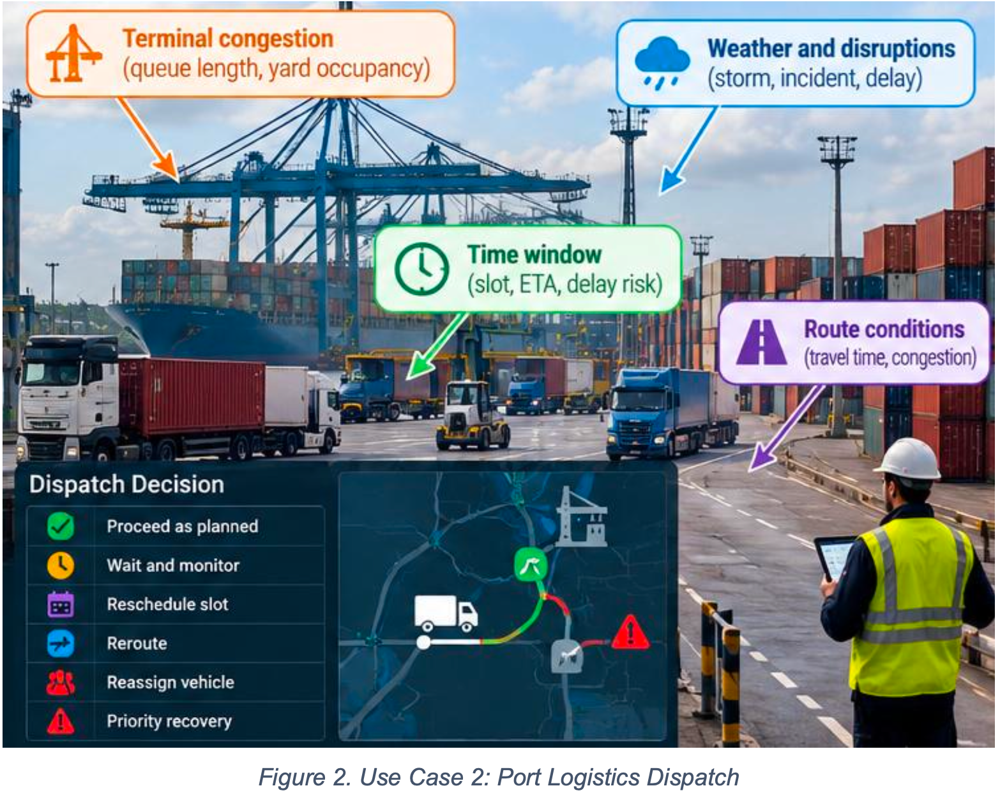

In [5]:
from pathlib import Path
from IPython.display import display, Image

BASE_DIR = Path.cwd()
DATA_PATH = Path("../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/classification_logistics.csv")
FIGURE_PATH = BASE_DIR / "Figure_2_Port_Logistics_Dispatch_Use_Case.png"

if FIGURE_PATH.exists():
    display(Image(filename=str(FIGURE_PATH), width=1000))
else:
    print(f"Reference image not found at: {FIGURE_PATH}")


**Figure 1.** Supplied project use-case illustration for Port Logistics Dispatch. The visual is contextual rather than an analytical result.

In [6]:
# Core imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from pandas.plotting import parallel_coordinates

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.figsize"] = (10, 6)

PLOT_DIR = BASE_DIR / "plots-2"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Recommended_Dispatch_Action"
ID_COL = "Observation_ID"

def savefig(name, bbox_inches="tight"):
    path = PLOT_DIR / f"{name}.png"
    plt.savefig(path, dpi=300, bbox_inches=bbox_inches)
    print(f"Saved: {path}")

def show_and_save(name, bbox_inches="tight"):
    savefig(name, bbox_inches=bbox_inches)
    plt.show()


In [7]:
# Load the supplied dataset without modifying the source file
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded from: {DATA_PATH}")
print(f"Shape: {df.shape}")
display(df.head())


Dataset loaded from: ../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/classification_logistics.csv
Shape: (10250, 41)


,Observation_ID,Event_Timestamp,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,...,Alternative_Terminal_Available,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action
0,1,2027-04-29 06:20:00,Thu,Day,T1,C1,Container,Tractor_Unit,92.88,8.64,...,False,True,3.99,1.0,False,88.36,5.0,96.20,90.02,PRIORITY_RECOVERY
1,2,2027-06-27 14:36:00,Sun,Evening,T1,C4,Trailer,Tractor_Unit,88.66,26.61,...,False,False,NaN,0.0,False,89.85,5.0,94.98,68.10,PROCEED_AS_PLANNED
2,3,2026-12-02 22:51:00,Wed,Night,T4,C3,Trailer,Tractor_Unit,30.60,19.01,...,False,True,35.86,4.0,True,90.22,3.0,98.44,20.00,PROCEED_AS_PLANNED
3,4,2026-12-30 17:45:00,Wed,Evening,T2,C1,Container,Tractor_Unit,97.52,8.60,...,False,True,27.85,2.0,False,89.08,6.0,98.77,61.87,REASSIGN_VEHICLE
4,5,2027-02-01 00:14:00,Mon,Night,T3,C3,Swap_Body,Rigid_Truck,129.40,13.18,...,False,True,10.68,3.0,True,89.24,4.0,97.78,104.38,REASSIGN_VEHICLE


## 2. Dataset description and data dictionary

The project brief states that the dataset contains **10,000 dispatch cases**. The supplied CSV is independently checked below; any difference is reported rather than silently corrected.

The feature groups are interpreted according to the project brief:

- **Temporal/context:** timestamp, day, shift, terminal, corridor
- **Transport:** object and vehicle type, distance
- **Disruption:** weather, terminal/road incidents, congestion, delay, ETA uncertainty
- **Terminal handling:** yard occupancy, queue, gate processing
- **Slot:** window length and buffer
- **Operational readiness:** trailer, customs, vehicle technical status
- **Resource constraints:** driver hours, compatible vehicles, driver change
- **Alternatives:** alternative slot/terminal/route and route extra distance
- **Commercial/sustainability:** service-level penalty, CO₂
- **Target:** recommended dispatch action


In [8]:
# Dataset dimensions and structural checks
n_rows, n_cols = df.shape
print(f"Observed rows: {n_rows:,}")
print(f"Observed columns: {n_cols:,}")
print(f"Rows stated in project brief: 10,000")
print(f"Difference from brief: {n_rows - 10_000:+,}")

print("\nDuplicate Observation_ID values:", df[ID_COL].duplicated().sum())
print("Duplicate complete rows:", df.duplicated().sum())


Observed rows: 10,250
Observed columns: 41
Rows stated in project brief: 10,000
Difference from brief: +250

Duplicate Observation_ID values: 250
Duplicate complete rows: 196


In [9]:
# Data types
dtype_table = pd.DataFrame({
    "feature": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "missing_pct": (df.isna().mean() * 100).round(2).values,
    "unique_values": df.nunique(dropna=True).values
})
display(dtype_table)


,feature,dtype,non_null,missing,missing_pct,unique_values
0,Observation_ID,int64,10250,0,0.00,10000
1,Event_Timestamp,object,10250,0,0.00,9906
2,Day_of_Week,object,10146,104,1.01,35
3,Shift,object,10148,102,1.00,15
4,Terminal_ID,object,10148,102,1.00,4
5,Corridor_ID,object,10146,104,1.01,5
6,Transport_Object_Type,object,10148,102,1.00,3
7,Vehicle_Type,object,10146,104,1.01,21
8,Distance_to_Terminal_km,float64,10147,103,1.00,6791
9,Weather_Severity_Index,float64,10144,106,1.03,3884


In [10]:
# Numeric statistical profile
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_summary = df[numeric_cols].describe().T
numeric_summary["missing"] = df[numeric_cols].isna().sum()
numeric_summary["missing_pct"] = df[numeric_cols].isna().mean() * 100
display(numeric_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
Observation_ID,10250.0,4997.199,2887.196,1.00,2502.250,4997.500,7501.750,10000.00,0,0.000
Distance_to_Terminal_km,10147.0,73.052,74.899,5.00,35.365,54.660,86.030,842.05,103,1.005
Weather_Severity_Index,10144.0,17.197,13.918,0.02,6.938,13.405,23.600,98.01,106,1.034
Terminal_Incident_Severity,10144.0,0.210,0.570,0.00,0.000,0.000,0.000,3.00,106,1.034
Road_Incident_Severity,10149.0,0.175,0.517,0.00,0.000,0.000,0.000,3.00,101,0.985
Terminal_Congestion_Index,10149.0,49.385,16.207,0.00,37.970,47.990,60.140,100.00,101,0.985
Road_Congestion_Index,10150.0,47.989,19.498,0.00,33.610,45.220,61.185,100.00,100,0.976
Yard_Occupancy_pct,9779.0,67.174,10.615,32.11,60.000,66.920,74.400,100.00,471,4.595
Queue_Length_vehicles,9945.0,9.473,4.230,0.00,7.000,9.000,12.000,29.00,305,2.976
Gate_Processing_Time_min,9996.0,22.495,12.074,5.00,16.570,20.755,25.720,151.38,254,2.478


In [11]:
# Categorical/boolean profile
categorical_cols = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

cat_profile = []
for col in categorical_cols:
    vc = df[col].value_counts(dropna=False)
    top_value = vc.index[0] if len(vc) else np.nan
    cat_profile.append({
        "feature": col,
        "dtype": str(df[col].dtype),
        "unique_non_null": df[col].nunique(dropna=True),
        "missing": df[col].isna().sum(),
        "missing_pct": df[col].isna().mean() * 100,
        "most_common": top_value,
        "most_common_count": vc.iloc[0] if len(vc) else 0,
        "most_common_pct": vc.iloc[0] / len(df) * 100 if len(vc) else 0
    })
display(pd.DataFrame(cat_profile).round(3))


,feature,dtype,unique_non_null,missing,missing_pct,most_common,most_common_count,most_common_pct
0,Event_Timestamp,object,9906,0,0.000,2027-03-17 08:35:00,3,0.029
1,Day_of_Week,object,35,104,1.015,Tue,1468,14.322
2,Shift,object,15,102,0.995,Evening,3301,32.205
3,Terminal_ID,object,4,102,0.995,T1,3248,31.688
4,Corridor_ID,object,5,104,1.015,C2,2263,22.078
5,Transport_Object_Type,object,3,102,0.995,Trailer,4634,45.210
6,Vehicle_Type,object,21,104,1.015,Tractor_Unit,5956,58.107
7,Trailer_Ready,bool,2,0,0.000,True,9534,93.015
8,Customs_Status,object,3,101,0.985,Cleared,8265,80.634
9,Vehicle_Technical_Status,object,3,101,0.985,OK,9229,90.039


## 3. Missing-value analysis

Missingness is treated as an analytical finding, not something to hide during EDA. The project dataset intentionally contains missing values in several operational variables, including `Yard_Occupancy_pct`, `ETA_Uncertainty_min`, and `Alternative_Route_Extra_km`.

For Part 1, the raw data are retained. Imputation, encoding, and other preprocessing decisions belong to the subsequent modeling stage.

,missing_count,missing_pct
Alternative_Route_Extra_km,2218,21.64
ETA_Uncertainty_min,589,5.75
Yard_Occupancy_pct,471,4.60
Expected_Disruption_Duration_min,407,3.97
Current_Delay_min,308,3.00
Queue_Length_vehicles,305,2.98
Gate_Processing_Time_min,254,2.48
Historical_Route_Reliability_pct,204,1.99
Weather_Severity_Index,106,1.03
Terminal_Incident_Severity,106,1.03


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/01_missing_value_rate.png


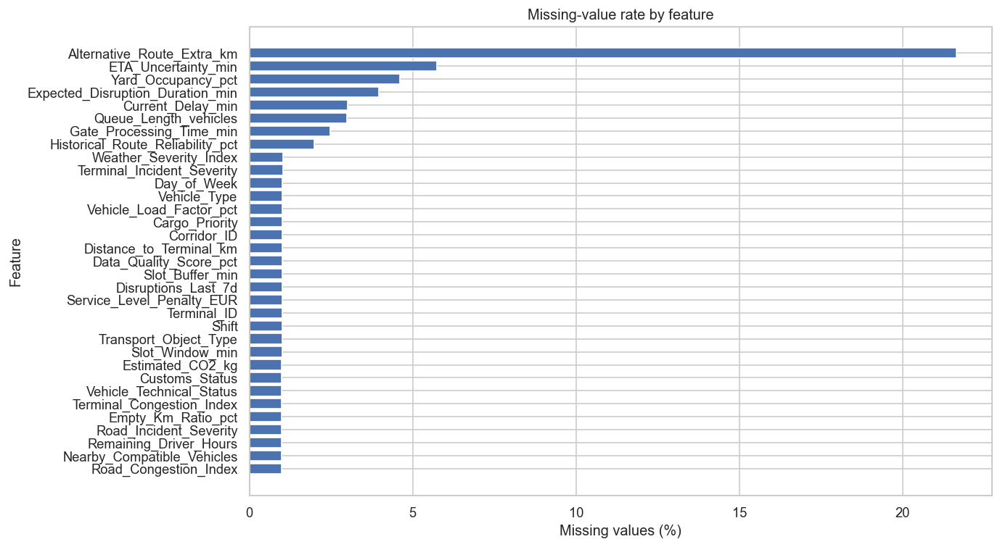

In [12]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})
display(missing_table[missing_table["missing_count"] > 0])

plt.figure(figsize=(11, 7))
m = missing_table[missing_table["missing_count"] > 0].sort_values("missing_pct")
plt.barh(m.index.astype(str), m["missing_pct"].values)
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Missing-value rate by feature")
show_and_save("01_missing_value_rate")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/02_missingness_pattern.png


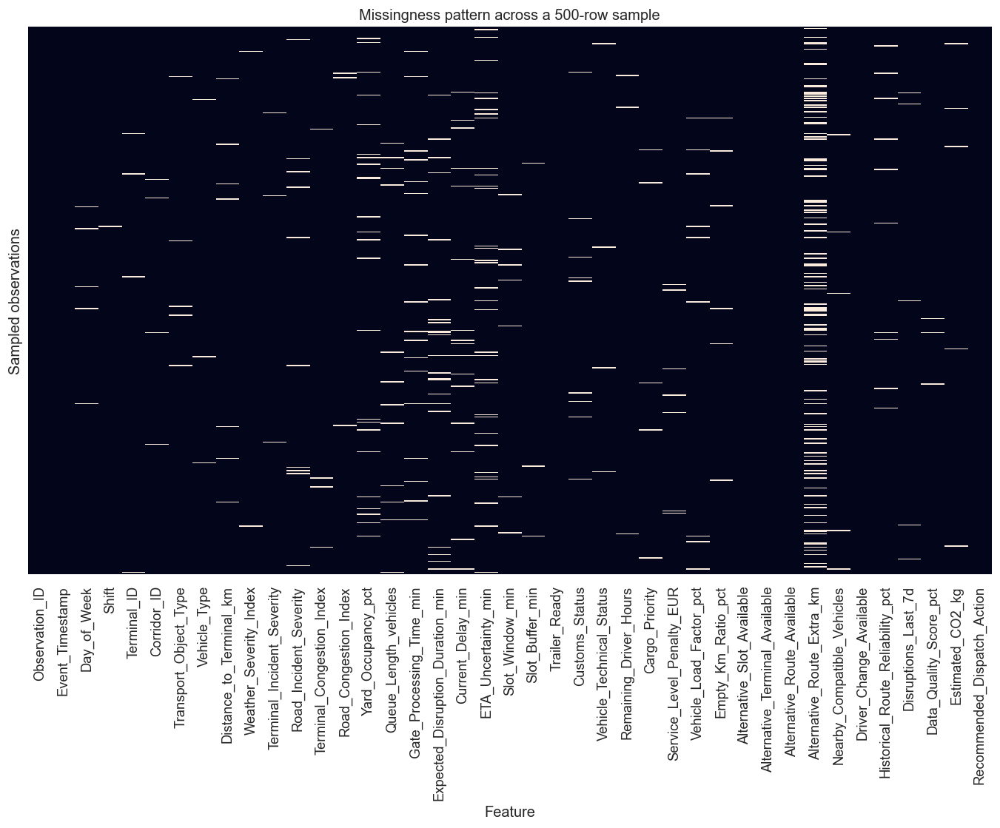

In [13]:
# Missingness pattern heatmap for a compact sample of rows
sample_for_missing = df.sample(min(500, len(df)), random_state=42)
plt.figure(figsize=(14, 8))
sns.heatmap(sample_for_missing.isna(), cbar=False, yticklabels=False)
plt.xlabel("Feature")
plt.ylabel("Sampled observations")
plt.title("Missingness pattern across a 500-row sample")
show_and_save("02_missingness_pattern")


## 4. Target variable: recommended dispatch action

The target has six operational classes. Class frequencies are examined before relationship analysis because class imbalance can affect how patterns are interpreted in later classification work.

,count,percentage
Recommended_Dispatch_Action,,
PROCEED_AS_PLANNED,2258,22.03
WAIT_AND_MONITOR,2196,21.42
PRIORITY_RECOVERY,1612,15.73
RESCHEDULE_SLOT,1531,14.94
REROUTE,1361,13.28
REASSIGN_VEHICLE,1292,12.60


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/03_target_class_distribution.png


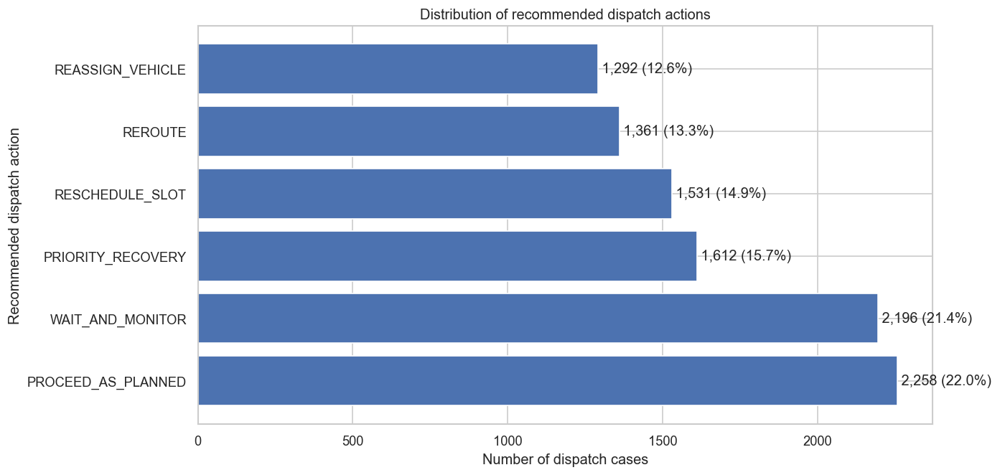

In [14]:
target_counts = df[TARGET].value_counts(dropna=False)
target_pct = target_counts / len(df) * 100
target_table = pd.DataFrame({"count": target_counts, "percentage": target_pct.round(2)})
display(target_table)

plt.figure(figsize=(11, 6))
order = target_counts.index.tolist()
plt.barh(order, target_counts.values)
plt.xlabel("Number of dispatch cases")
plt.ylabel("Recommended dispatch action")
plt.title("Distribution of recommended dispatch actions")
for i, v in enumerate(target_counts.values):
    plt.text(v, i, f" {v:,} ({v/len(df)*100:.1f}%)", va="center")
show_and_save("03_target_class_distribution")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/04_target_class_share.png


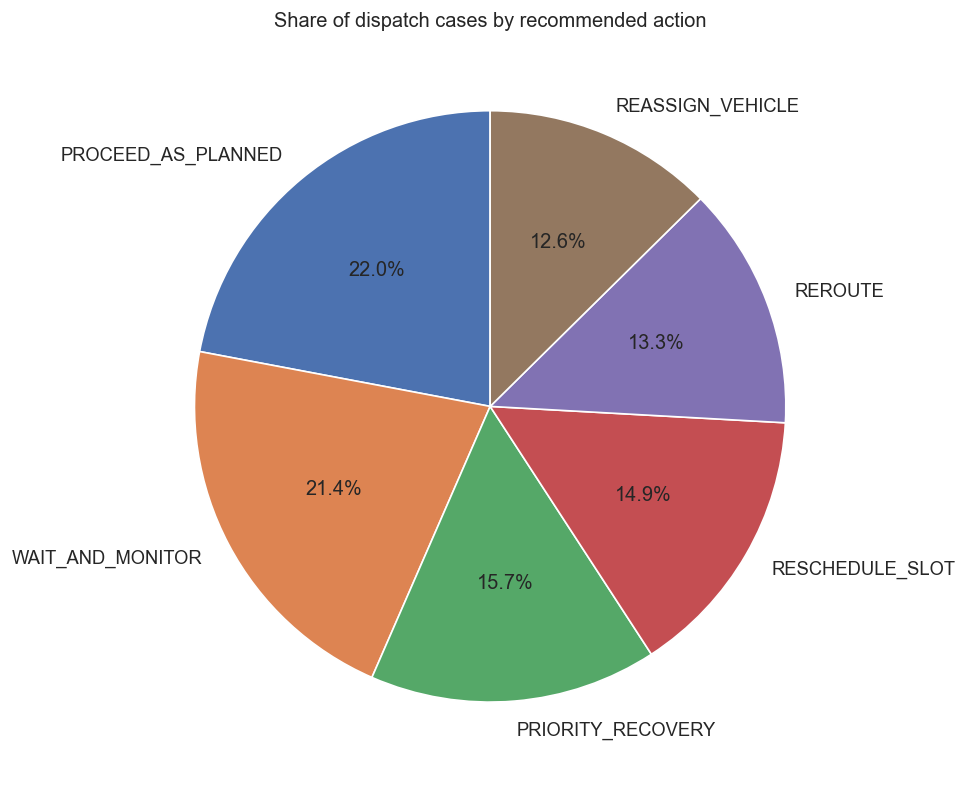

In [15]:
plt.figure(figsize=(8, 8))
plt.pie(target_counts.values, labels=target_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of dispatch cases by recommended action")
show_and_save("04_target_class_share")


## 5. Categorical-variable analysis

The rubric specifically requests categorical analysis using bar charts/histograms/pie charts. The following plots examine the major operational categorical variables and their class composition.

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_day_of_week.png


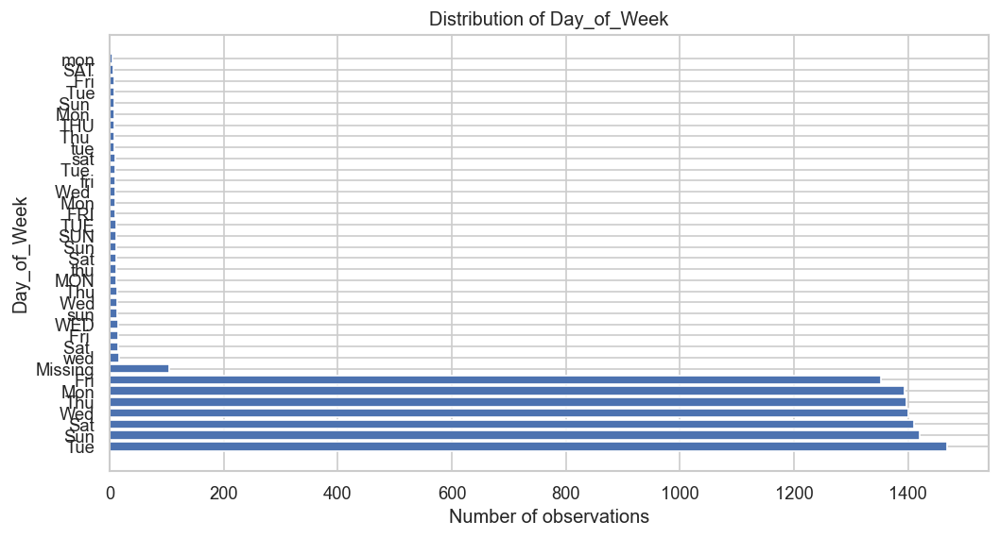

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_shift.png


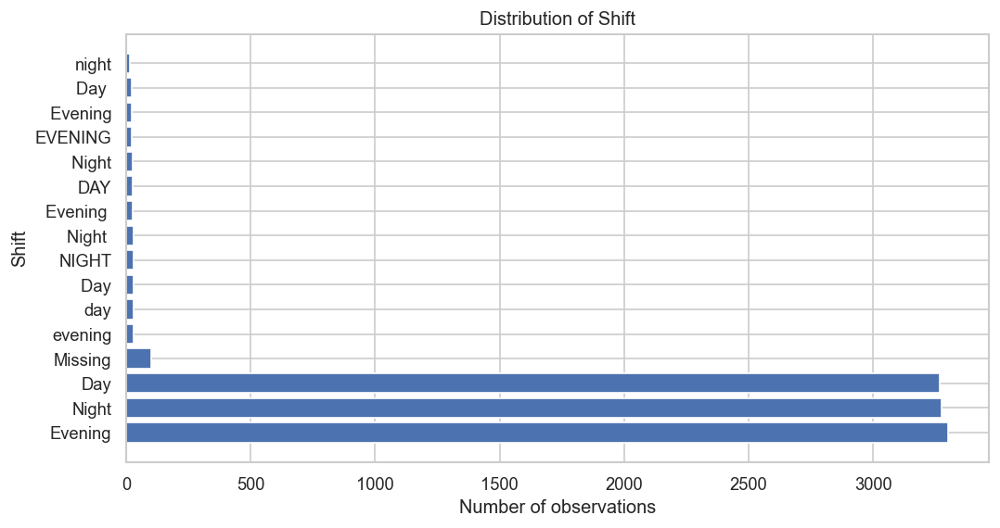

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_terminal_id.png


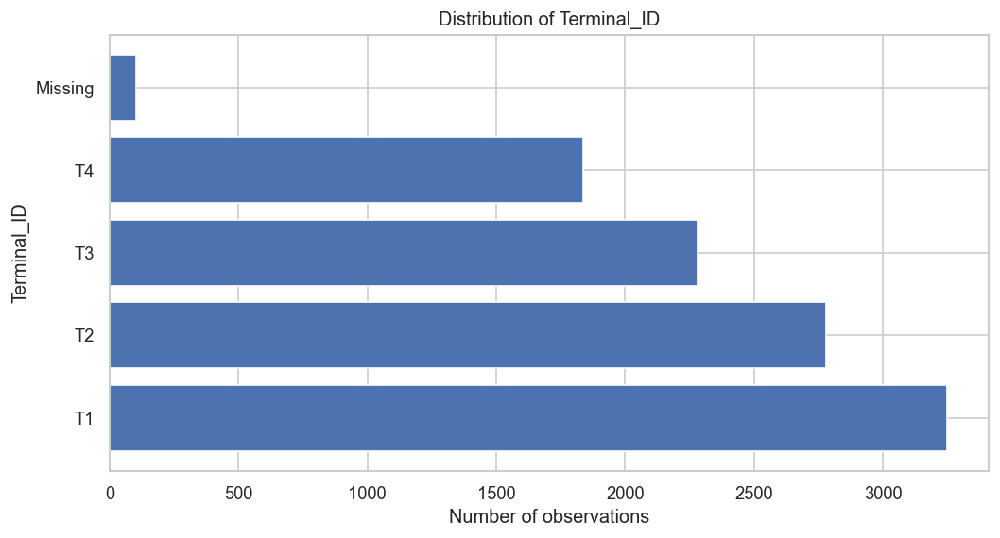

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_corridor_id.png


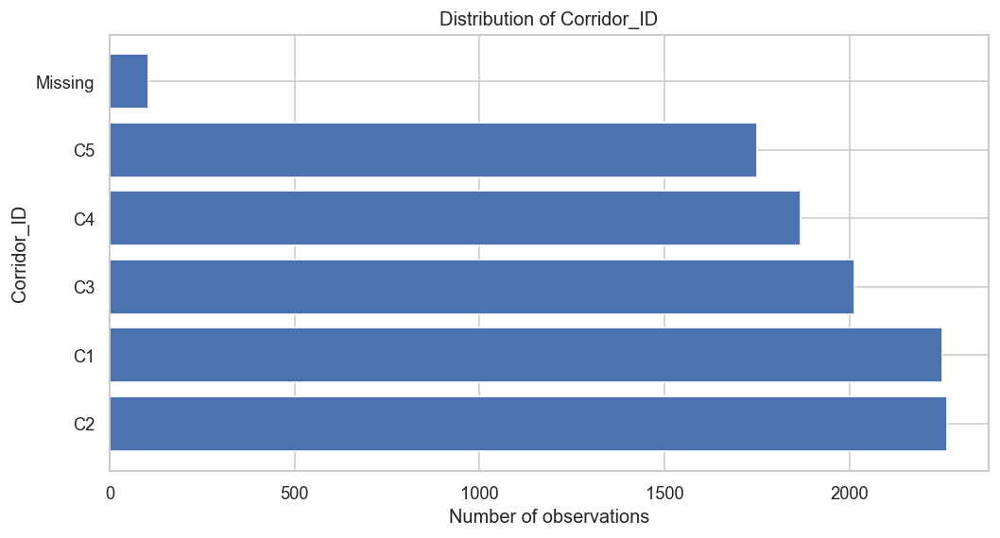

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_transport_object_type.png


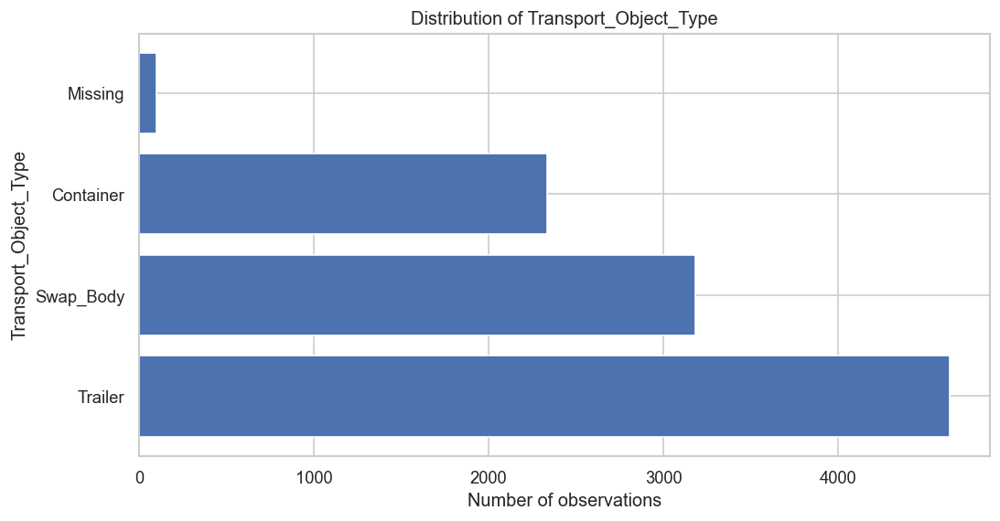

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_vehicle_type.png


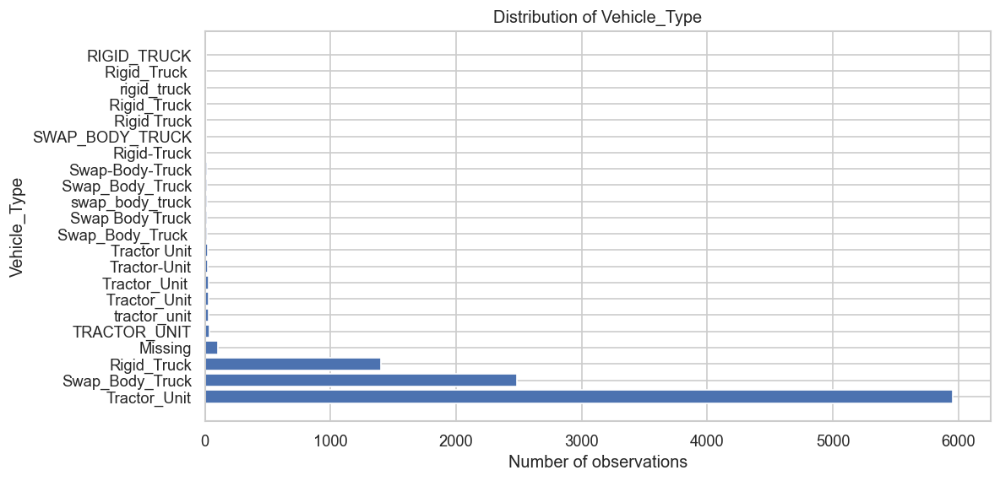

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_customs_status.png


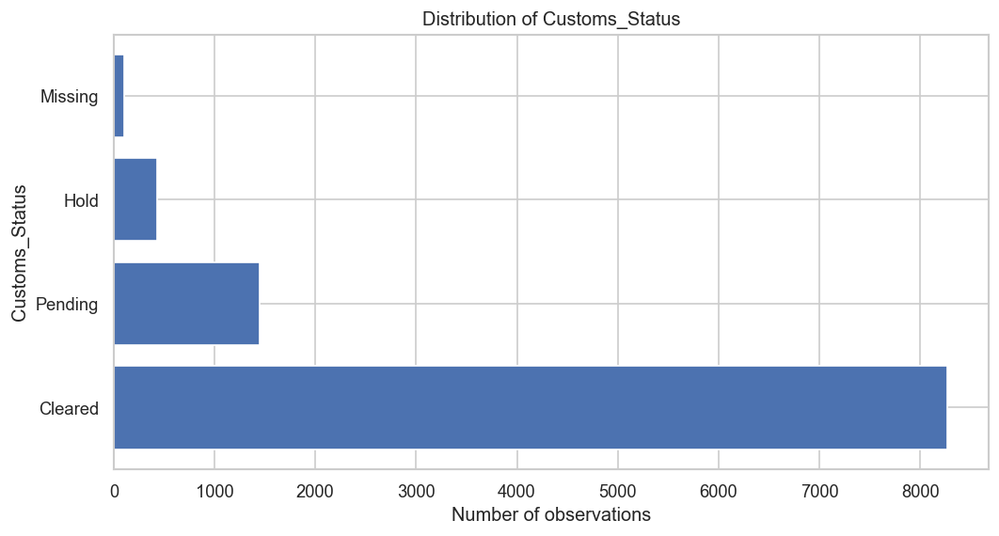

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/05_categorical_vehicle_technical_status.png


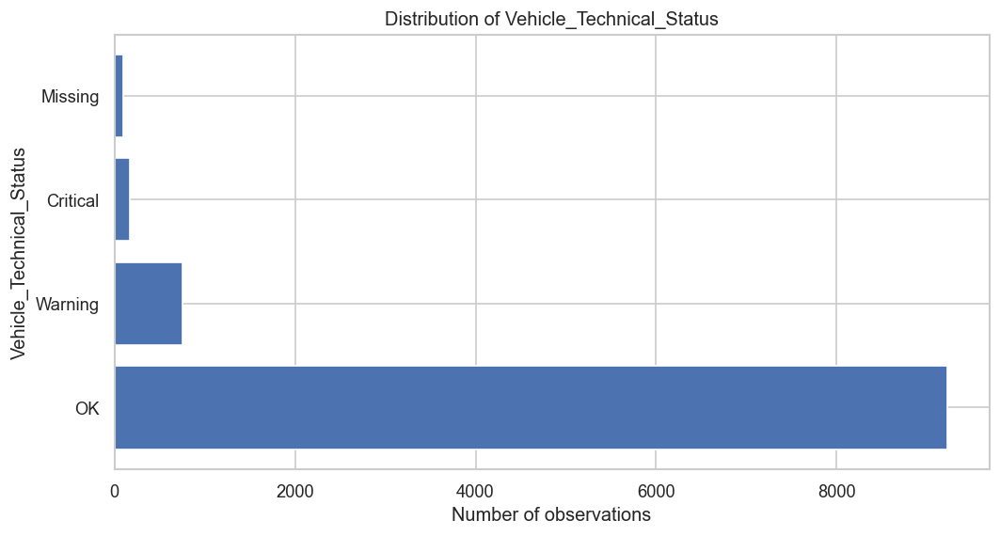

In [16]:
cat_plot_cols = ['Day_of_Week', 'Shift', 'Terminal_ID', 'Corridor_ID', 'Transport_Object_Type', 'Vehicle_Type', 'Customs_Status', 'Vehicle_Technical_Status']

for col in cat_plot_cols:
    counts = df[col].fillna("Missing").value_counts()
    plt.figure(figsize=(10, 5))
    plt.barh(counts.index.astype(str), counts.values)
    plt.xlabel("Number of observations")
    plt.ylabel(col)
    plt.title(f"Distribution of {col}")
    show_and_save(f"05_categorical_{col.lower()}")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/06_boolean_operational_variables.png


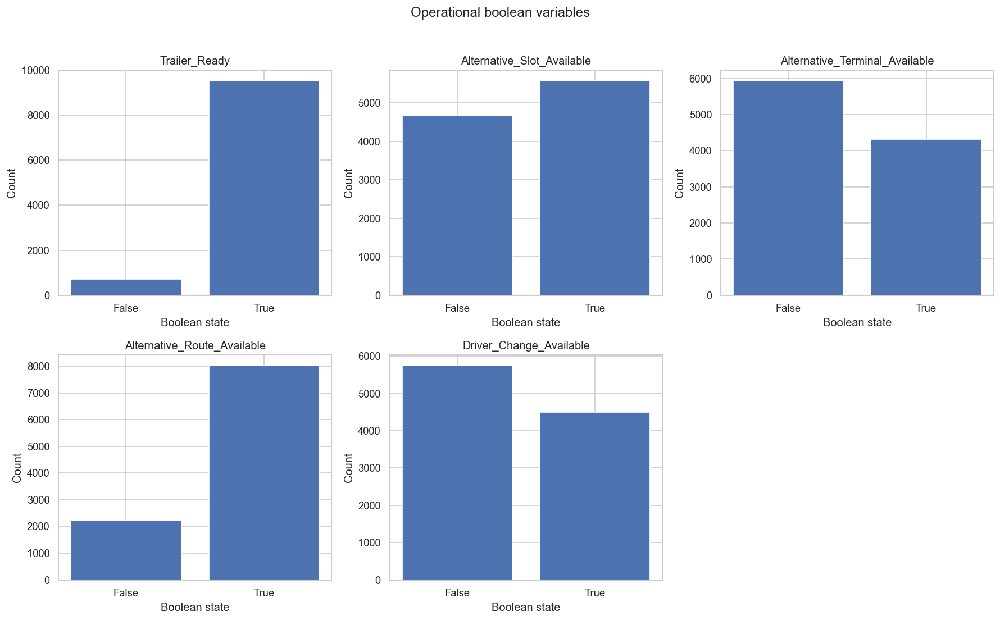

In [17]:
# Boolean operational readiness / alternatives
bool_cols = ["Trailer_Ready", "Alternative_Slot_Available", "Alternative_Terminal_Available",
             "Alternative_Route_Available", "Driver_Change_Available"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for ax, col in zip(axes, bool_cols):
    counts = df[col].fillna(False).value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(col)
    ax.set_xlabel("Boolean state")
    ax.set_ylabel("Count")
for ax in axes[len(bool_cols):]:
    ax.axis("off")
plt.suptitle("Operational boolean variables", y=1.02)
plt.tight_layout()
show_and_save("06_boolean_operational_variables")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/07_target_composition_by_terminal_id.png


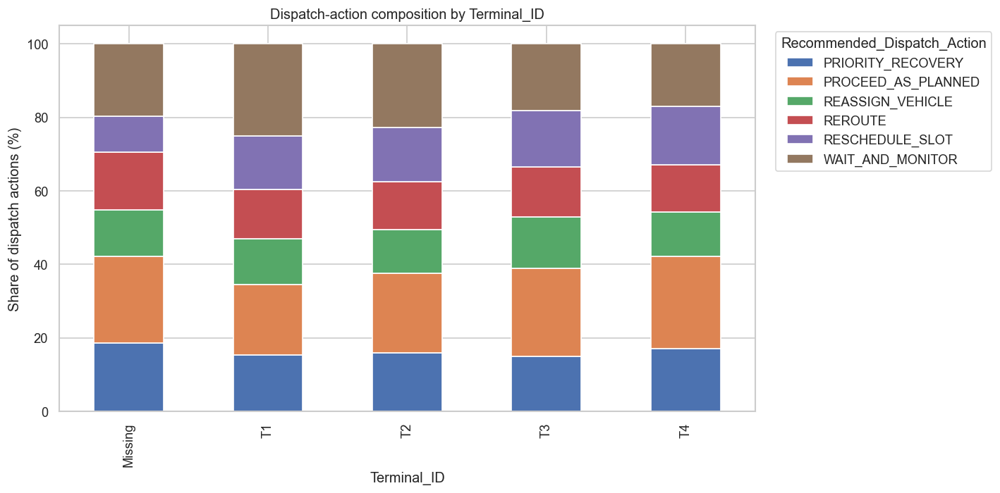

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/07_target_composition_by_corridor_id.png


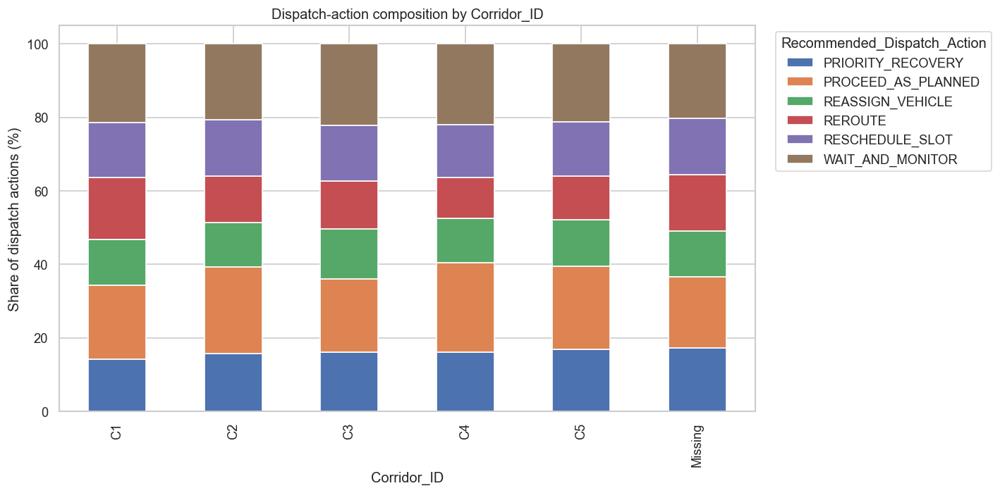

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/07_target_composition_by_shift.png


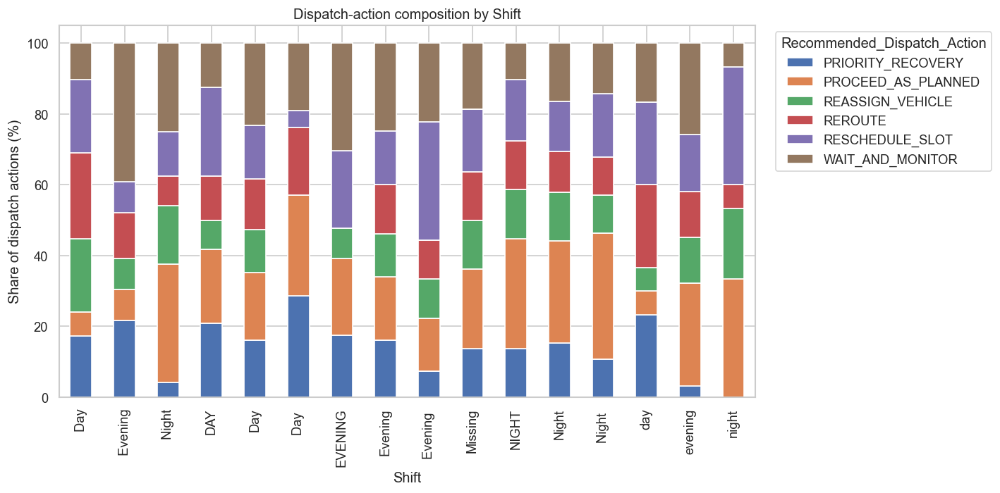

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/07_target_composition_by_transport_object_type.png


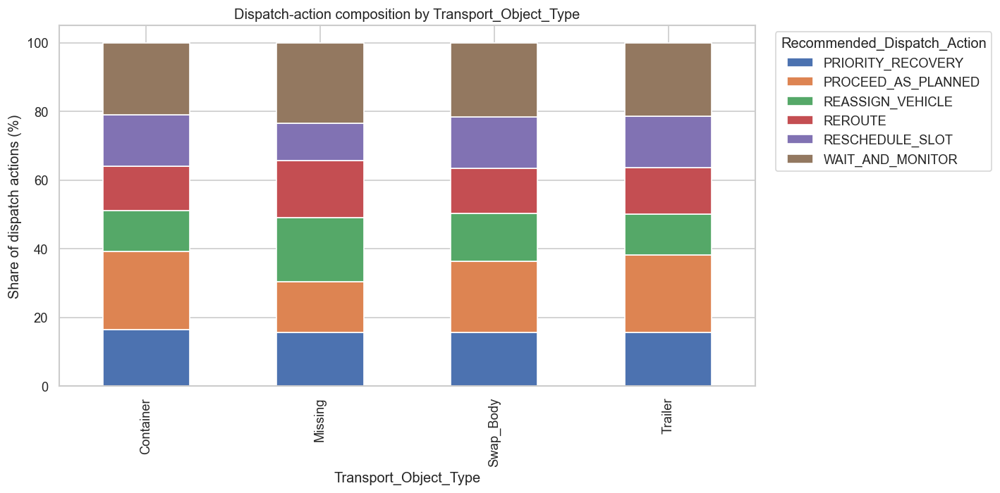

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/07_target_composition_by_vehicle_technical_status.png


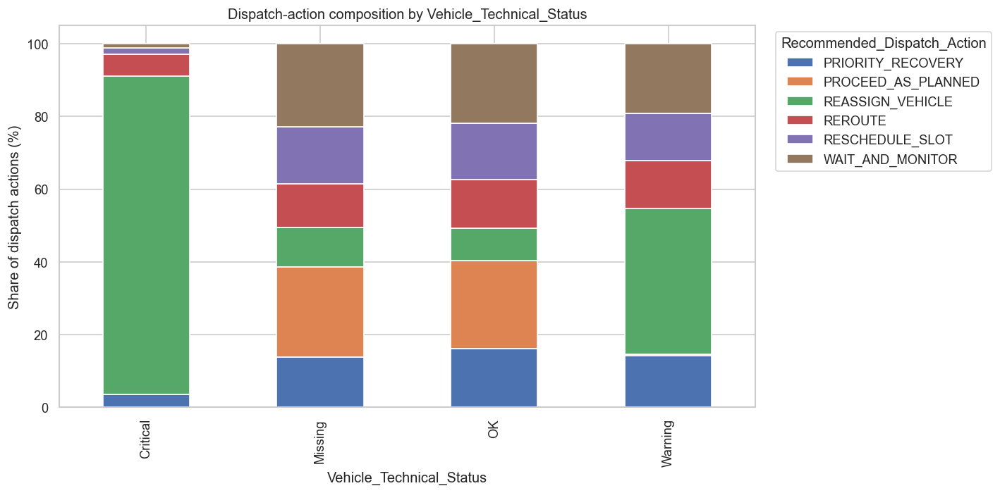

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/07_target_composition_by_customs_status.png


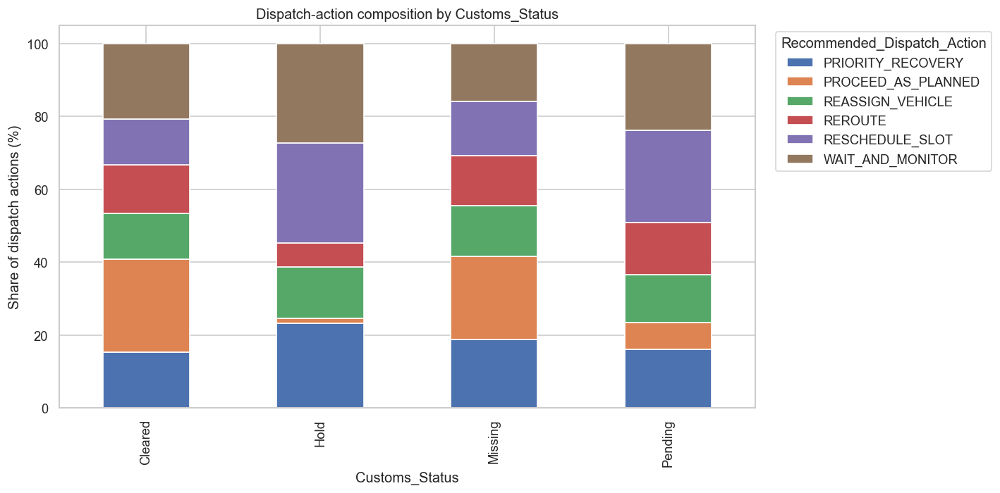

In [18]:
# Target composition by major categorical variables
for col in ["Terminal_ID", "Corridor_ID", "Shift", "Transport_Object_Type", "Vehicle_Technical_Status", "Customs_Status"]:
    ct = pd.crosstab(df[col].fillna("Missing"), df[TARGET], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, figsize=(12, 6))
    plt.ylabel("Share of dispatch actions (%)")
    plt.xlabel(col)
    plt.title(f"Dispatch-action composition by {col}")
    plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    show_and_save(f"07_target_composition_by_{col.lower()}")


## 6. Numerical-variable analysis

The project rubric requires histograms/KDE, box plots, and violin plots. The analysis below uses the numerical operational variables rather than identifiers. Variables are grouped into readable panels so the plots remain interpretable.

In [19]:
# Numeric features used for distribution, outlier, and relationship analysis
numeric_features = [c for c in numeric_cols if c != ID_COL]
print(f"Numeric operational features analysed: {len(numeric_features)}")


Numeric operational features analysed: 25


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/08_numerical_histograms_kde.png


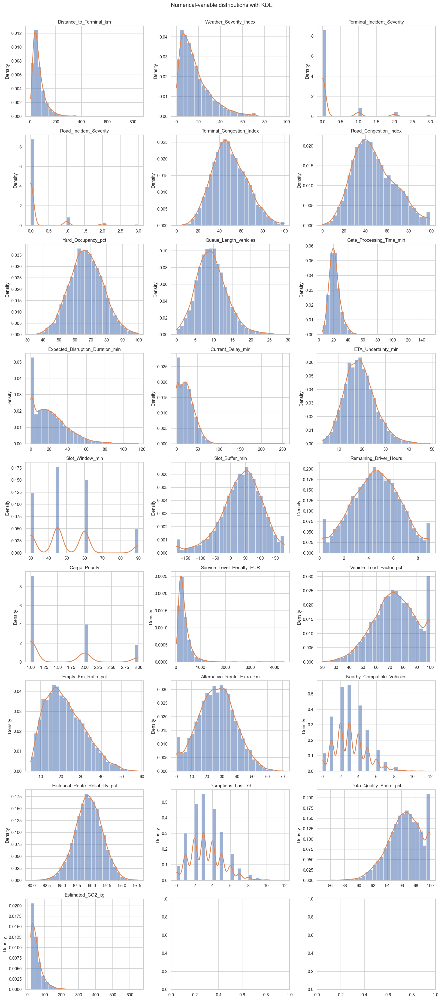

In [20]:
# Histograms + KDE (matplotlib + scipy for compatibility)
ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    values = df[col].dropna().to_numpy()
    ax.hist(values, bins=30, density=True, alpha=0.55)
    if len(values) > 1 and np.std(values) > 0:
        kde = stats.gaussian_kde(values)
        x_grid = np.linspace(values.min(), values.max(), 300)
        ax.plot(x_grid, kde(x_grid), linewidth=2)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Density")
fig.suptitle("Numerical-variable distributions with KDE", y=1.002)
plt.tight_layout()
show_and_save("08_numerical_histograms_kde")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/09_numerical_boxplots.png


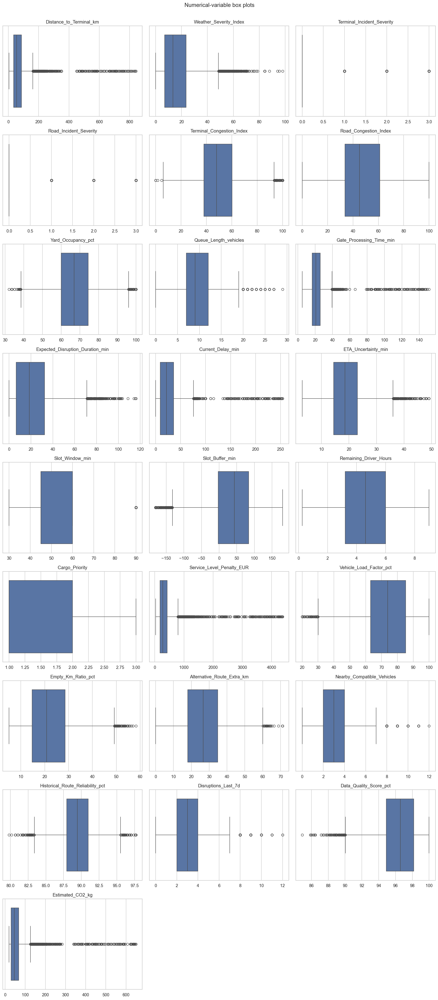

In [21]:
# Box plots
ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes[len(numeric_features):]:
    ax.axis("off")
fig.suptitle("Numerical-variable box plots", y=1.002)
plt.tight_layout()
show_and_save("09_numerical_boxplots")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/10_selected_violin_plots_by_target.png


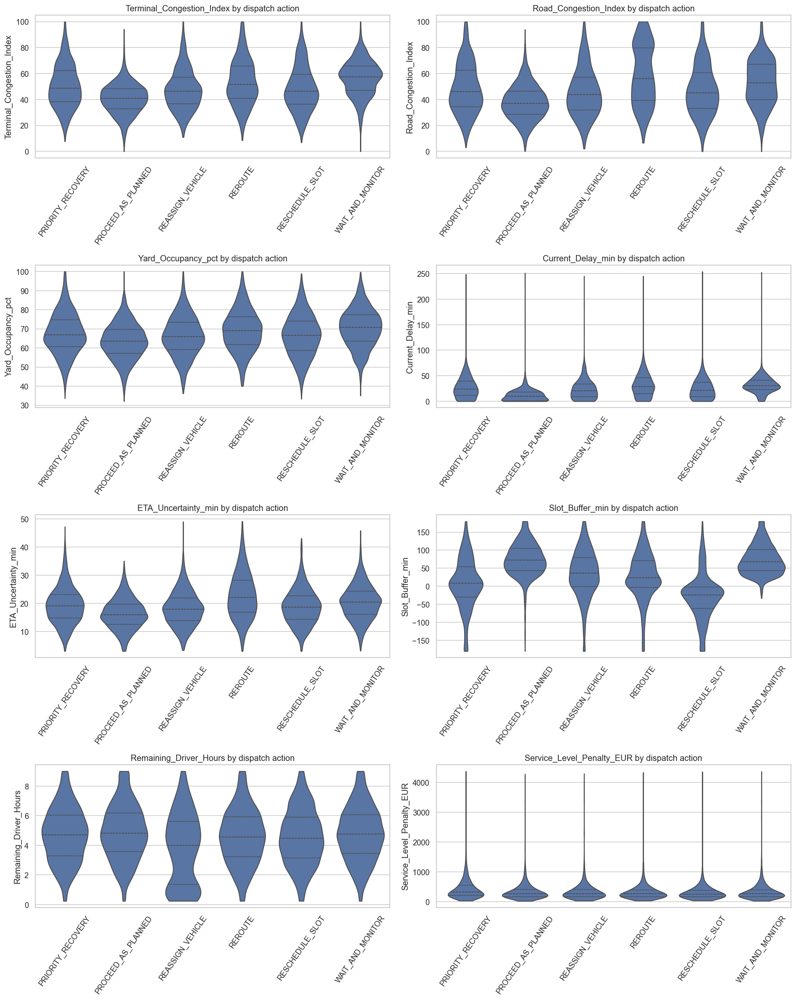

In [22]:
# Violin plots against the six-class target for selected operational drivers
violin_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index", "Yard_Occupancy_pct",
    "Current_Delay_min", "ETA_Uncertainty_min", "Slot_Buffer_min",
    "Remaining_Driver_Hours", "Service_Level_Penalty_EUR"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for ax, col in zip(axes.ravel(), violin_features):
    sns.violinplot(data=df, x=TARGET, y=col, ax=ax, inner="quartile", cut=0)
    ax.set_title(col + " by dispatch action")
    ax.tick_params(axis="x", rotation=55)
    ax.set_xlabel("")
for ax in axes.ravel()[len(violin_features):]:
    ax.axis("off")
plt.tight_layout()
show_and_save("10_selected_violin_plots_by_target")


## 7. Outlier detection

Potential outliers are identified with the 1.5×IQR rule as a screening method. They are **not automatically removed**. NIST notes that unusual observations may represent errors, random variation, or scientifically/operationally meaningful cases, so they should be investigated before deletion.

This distinction is important in a dispatch dataset: extreme delay, congestion, or disruption values may be precisely the situations in which exceptional dispatch actions occur.

,feature,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct
2,Terminal_Incident_Severity,0.000,0.000,0.000,0.000,0.000,1443,14.078
3,Road_Incident_Severity,0.000,0.000,0.000,0.000,0.000,1255,12.244
12,Slot_Window_min,45.000,60.000,15.000,22.500,82.500,993,9.688
0,Distance_to_Terminal_km,35.365,86.030,50.665,-40.633,162.028,598,5.834
16,Service_Level_Penalty_EUR,179.230,426.143,246.913,-191.139,796.511,595,5.805
24,Estimated_CO2_kg,29.270,68.050,38.780,-28.900,126.220,572,5.580
1,Weather_Severity_Index,6.938,23.600,16.662,-18.056,48.594,400,3.902
8,Gate_Processing_Time_min,16.570,25.720,9.150,2.845,39.445,325,3.171
13,Slot_Buffer_min,-2.572,84.040,86.613,-132.491,213.959,240,2.341
22,Disruptions_Last_7d,2.000,4.000,2.000,-1.000,7.000,230,2.244


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/11_iqr_outlier_rates.png


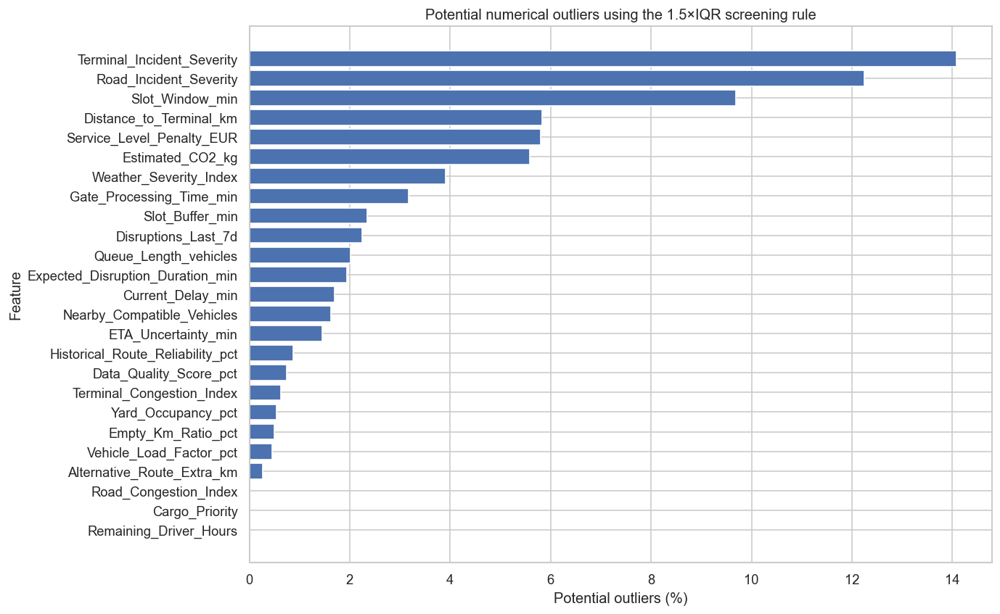

In [23]:
outlier_rows = []
for col in numeric_features:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": mask.mean() * 100
    })

outlier_table = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)
display(outlier_table.round(3))

plt.figure(figsize=(11, 8))
plot_out = outlier_table.sort_values("outlier_pct")
plt.barh(plot_out["feature"].astype(str), plot_out["outlier_pct"].values)
plt.xlabel("Potential outliers (%)")
plt.ylabel("Feature")
plt.title("Potential numerical outliers using the 1.5×IQR screening rule")
show_and_save("11_iqr_outlier_rates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/12_outliers_by_dispatch_action.png


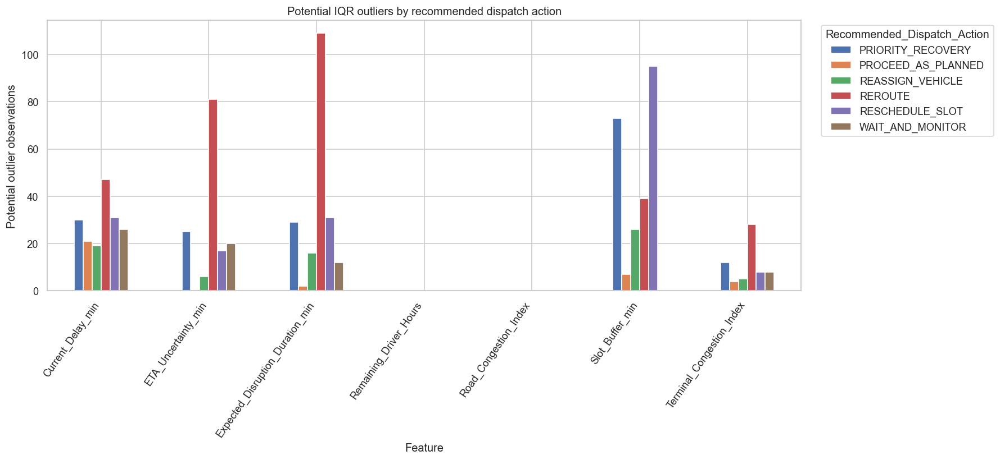

In [24]:
# Outlier count by dispatch action for key operational variables
key_outlier_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index", "Current_Delay_min",
    "ETA_Uncertainty_min", "Slot_Buffer_min", "Remaining_Driver_Hours",
    "Expected_Disruption_Duration_min"
]

records = []
for col in key_outlier_features:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    tmp = df.loc[mask, TARGET].value_counts()
    for cls in target_counts.index:
        records.append({"feature": col, "action": cls, "count": int(tmp.get(cls, 0))})

outlier_by_target = pd.DataFrame(records)
pivot = outlier_by_target.pivot(index="feature", columns="action", values="count")
pivot.plot(kind="bar", figsize=(15, 7))
plt.xlabel("Feature")
plt.ylabel("Potential outlier observations")
plt.title("Potential IQR outliers by recommended dispatch action")
plt.xticks(rotation=55, ha="right")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("12_outliers_by_dispatch_action")


## 8. Relationships among variables

The rubric explicitly requests relationship analysis. The following sections examine:

- Pearson correlation among numeric operational variables
- A scatter/pair plot using a representative subset
- Parallel coordinates for selected operational dimensions
- A bubble chart linking congestion, delay, and service-level exposure
- Target-related binned rates for variables that are operationally meaningful

Correlation is treated as a descriptive association, not proof of causality.

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/13_correlation_heatmap.png


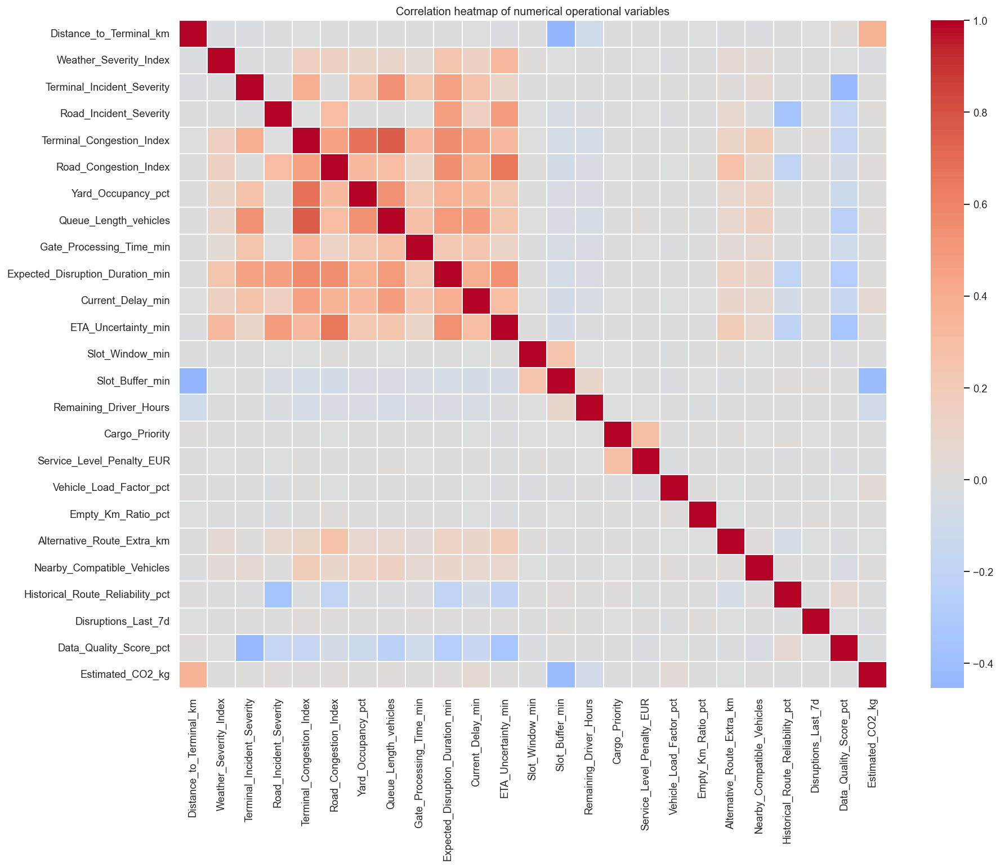

In [25]:
corr = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation heatmap of numerical operational variables")
plt.tight_layout()
show_and_save("13_correlation_heatmap")


In [26]:
# Identify strongest absolute correlations for discussion
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .reset_index()
)
corr_pairs.columns = ["feature_1", "feature_2", "pearson_r"]
corr_pairs["abs_r"] = corr_pairs["pearson_r"].abs()
display(corr_pairs.sort_values("abs_r", ascending=False).head(20).round(3))


,feature_1,feature_2,pearson_r,abs_r
92,Terminal_Congestion_Index,Queue_Length_vehicles,0.759,0.759
91,Terminal_Congestion_Index,Yard_Occupancy_pct,0.672,0.672
115,Road_Congestion_Index,ETA_Uncertainty_min,0.653,0.653
94,Terminal_Congestion_Index,Expected_Disruption_Duration_min,0.553,0.553
113,Road_Congestion_Index,Expected_Disruption_Duration_min,0.546,0.546
181,Expected_Disruption_Duration_min,ETA_Uncertainty_min,0.543,0.543
129,Yard_Occupancy_pct,Queue_Length_vehicles,0.539,0.539
51,Terminal_Incident_Severity,Queue_Length_vehicles,0.539,0.539
148,Queue_Length_vehicles,Expected_Disruption_Duration_min,0.497,0.497
149,Queue_Length_vehicles,Current_Delay_min,0.483,0.483


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/14_pairplot_selected_operational_variables.png


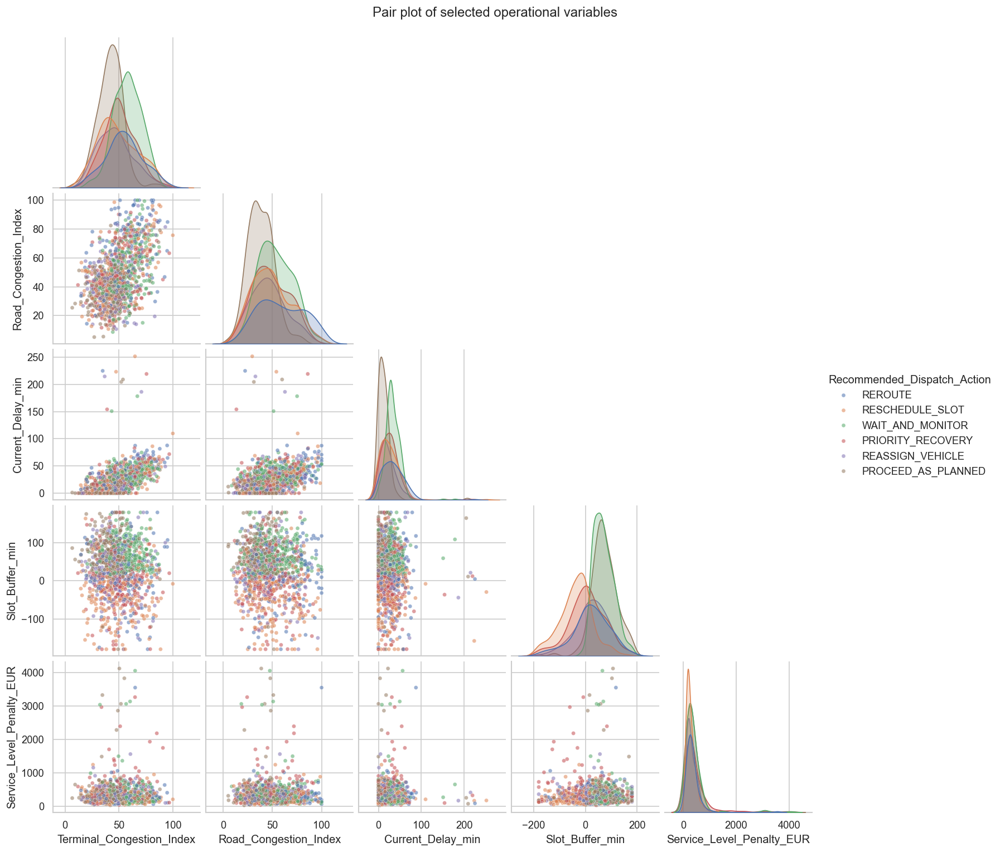

In [27]:
# Pair plot on a carefully selected operational subset.
pair_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "Slot_Buffer_min", "Service_Level_Penalty_EUR"
]
pair_sample = df[pair_features + [TARGET]].dropna().sample(min(1200, len(df.dropna())), random_state=42)

g = sns.pairplot(
    pair_sample,
    vars=pair_features,
    hue=TARGET,
    corner=True,
    plot_kws={"s": 18, "alpha": 0.55}
)
g.fig.suptitle("Pair plot of selected operational variables", y=1.02)
g.fig.savefig(PLOT_DIR / "14_pairplot_selected_operational_variables.png", dpi=300, bbox_inches="tight")
print(f"Saved: {PLOT_DIR / '14_pairplot_selected_operational_variables.png'}")
plt.show()


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/15_parallel_coordinates.png


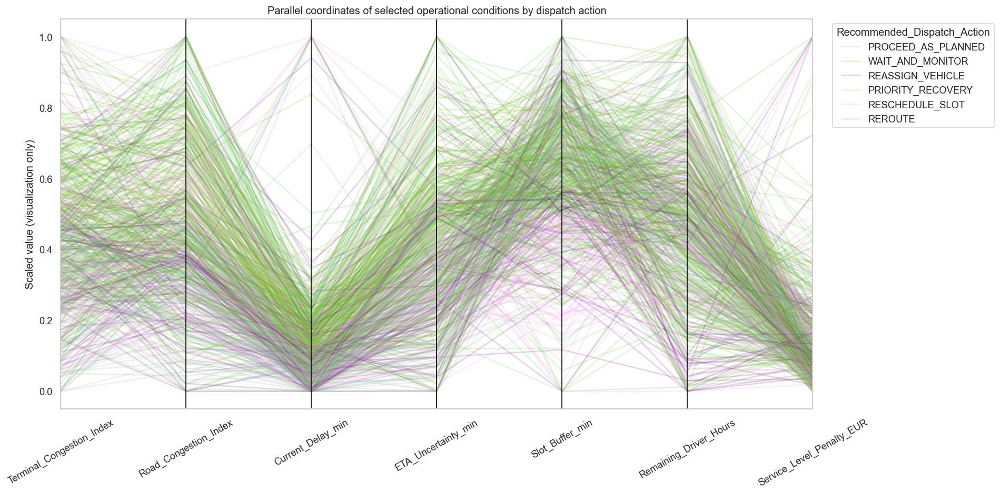

In [28]:
# Parallel coordinates on normalized selected variables
pc_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "ETA_Uncertainty_min",
    "Slot_Buffer_min", "Remaining_Driver_Hours",
    "Service_Level_Penalty_EUR"
]
pc = df[pc_features + [TARGET]].dropna().sample(min(600, len(df.dropna())), random_state=42).copy()

# Robust min-max scaling for visualization only
for col in pc_features:
    lo, hi = pc[col].quantile(0.01), pc[col].quantile(0.99)
    pc[col] = pc[col].clip(lo, hi)
    pc[col] = (pc[col] - pc[col].min()) / (pc[col].max() - pc[col].min())

plt.figure(figsize=(16, 8))
parallel_coordinates(pc, TARGET, alpha=0.18)
plt.title("Parallel coordinates of selected operational conditions by dispatch action")
plt.ylabel("Scaled value (visualization only)")
plt.xticks(rotation=30)
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("15_parallel_coordinates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/16_bubble_congestion_delay_penalty.png


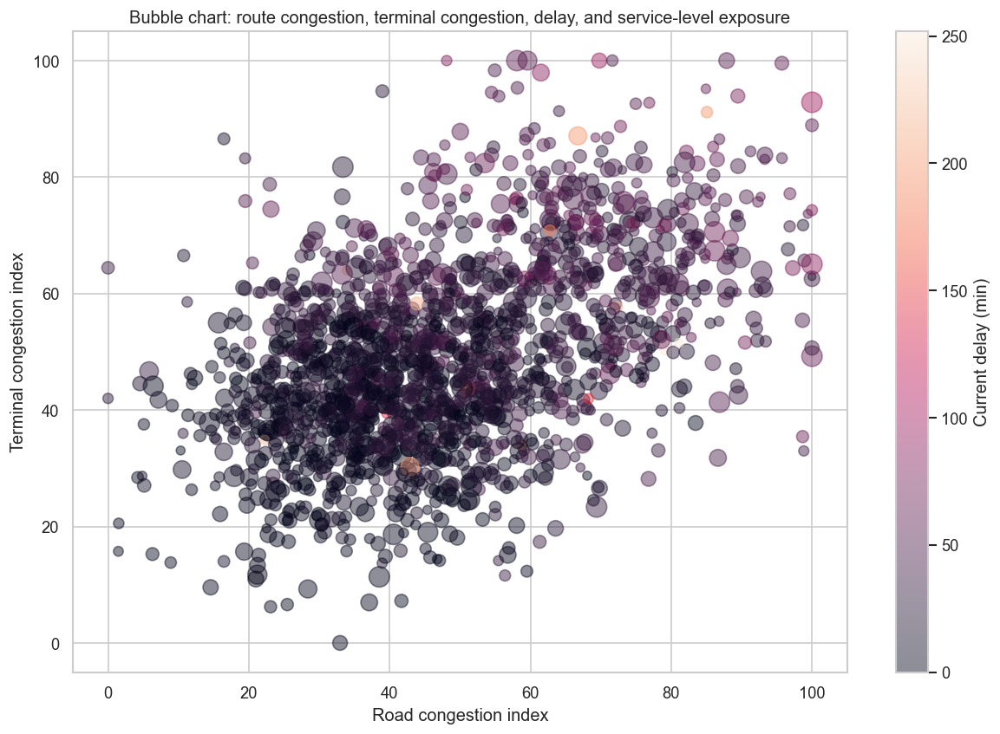

In [29]:
# Bubble chart: road congestion vs terminal congestion,
# bubble size = service-level penalty, color = current delay
bubble = df[[
    "Road_Congestion_Index", "Terminal_Congestion_Index",
    "Service_Level_Penalty_EUR", "Current_Delay_min", TARGET
]].dropna().sample(min(1800, df.dropna().shape[0]), random_state=42)

plt.figure(figsize=(12, 8))
sizes = 20 + 180 * (bubble["Service_Level_Penalty_EUR"] / bubble["Service_Level_Penalty_EUR"].quantile(0.95)).clip(0, 1)
sc = plt.scatter(
    bubble["Road_Congestion_Index"],
    bubble["Terminal_Congestion_Index"],
    s=sizes,
    c=bubble["Current_Delay_min"],
    alpha=0.45
)
plt.colorbar(sc, label="Current delay (min)")
plt.xlabel("Road congestion index")
plt.ylabel("Terminal congestion index")
plt.title("Bubble chart: route congestion, terminal congestion, delay, and service-level exposure")
show_and_save("16_bubble_congestion_delay_penalty")


## 9. Operational relationship analysis by target class

For a classification problem, the most useful EDA questions are often class-conditional:

- Does increasing congestion coincide with a changing action mix?
- Does negative slot buffer correspond to more recovery/rescheduling actions?
- Are technical warnings associated with vehicle reassignment?
- Does low remaining driver time coincide with particular operational responses?
- Does the availability of alternative routes/terminals alter the action distribution?

These are descriptive questions; the notebook does not claim that any feature causes the target.

In [30]:
# Numeric feature distributions summarized by target class
target_numeric_summary = df.groupby(TARGET)[[
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "ETA_Uncertainty_min",
    "Slot_Buffer_min", "Remaining_Driver_Hours",
    "Service_Level_Penalty_EUR", "Estimated_CO2_kg"
]].agg(["mean", "median"]).round(2)

display(target_numeric_summary)


Terminal_Congestion_Index         \
                                                 mean median   
Recommended_Dispatch_Action                                    
PRIORITY_RECOVERY                               50.50  48.80   
PROCEED_AS_PLANNED                              40.63  40.94   
REASSIGN_VEHICLE                                47.74  46.32   
REROUTE                                         53.51  51.72   
RESCHEDULE_SLOT                                 48.54  46.36   
WAIT_AND_MONITOR                                56.57  57.49   

                            Road_Congestion_Index        Current_Delay_min  \
                                             mean median              mean   
Recommended_Dispatch_Action                                                  
PRIORITY_RECOVERY                           48.63  46.27             27.86   
PROCEED_AS_PLANNED                          37.94  37.12             12.85   
REASSIGN_VEHICLE                            45.58  43.90             24.40   
REROUTE                                     58.60  56.07             32.22   
RESCHEDULE_SLOT                             47.38  45.20             26.30   
WAIT_AND_MONITOR                            53.09  52.97             32.82   

                                   ETA_Uncertainty_min        Slot_Buffer_min  \
                            median                mean median            mean   
Recommended_Dispatch_Action                                                     
PRIORITY_RECOVERY            24.02               19.27  19.02            7.58   
PROCEED_AS_PLANNED            9.57               16.24  15.96           73.75   
REASSIGN_VEHICLE             20.43               18.14  17.90           34.17   
REROUTE                      28.98               22.76  22.00           27.15   
RESCHEDULE_SLOT              21.40               18.82  18.59          -28.33   
WAIT_AND_MONITOR             30.44               20.40  20.41           73.96   

                                   Remaining_Driver_Hours         \
                            median                   mean median   
Recommended_Dispatch_Action                                        
PRIORITY_RECOVERY             8.12                   4.71   4.71   
PROCEED_AS_PLANNED           71.98                   4.88   4.82   
REASSIGN_VEHICLE             35.86                   3.77   3.99   
REROUTE                      23.33                   4.58   4.56   
RESCHEDULE_SLOT             -24.13                   4.55   4.49   
WAIT_AND_MONITOR             67.63                   4.79   4.75   

                            Service_Level_Penalty_EUR          \
                                                 mean  median   
Recommended_Dispatch_Action                                     
PRIORITY_RECOVERY                              450.59  327.60   
PROCEED_AS_PLANNED                             362.99  270.19   
REASSIGN_VEHICLE                               364.01  269.27   
REROUTE                                        342.03  267.07   
RESCHEDULE_SLOT                                334.82  255.29   
WAIT_AND_MONITOR                               356.37  267.48   

                            Estimated_CO2_kg         
                                        mean median  
Recommended_Dispatch_Action                          
PRIORITY_RECOVERY                      69.08  56.02  
PROCEED_AS_PLANNED                     46.01  36.17  
REASSIGN_VEHICLE                       59.99  48.71  
REROUTE                                62.28  48.22  
RESCHEDULE_SLOT                        81.17  68.61  
WAIT_AND_MONITOR                       45.29  37.74

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/17_mean_operational_conditions_by_action.png


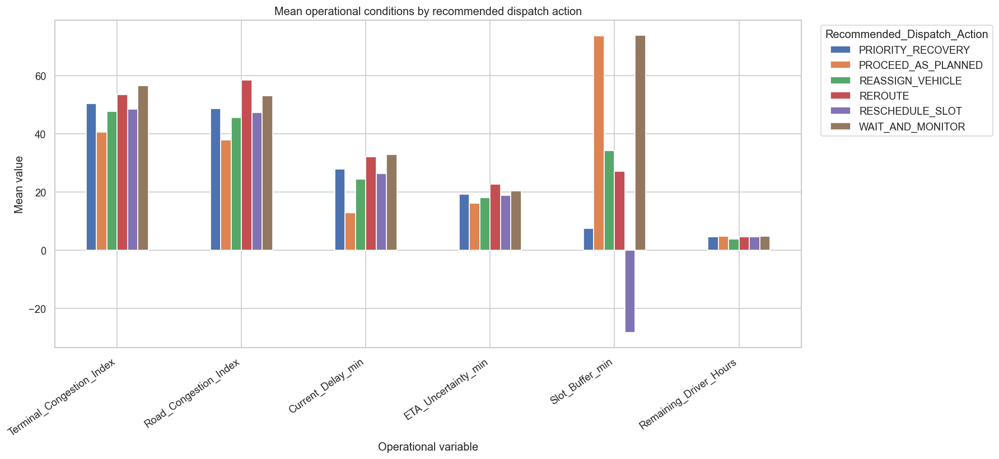

In [31]:
# Mean operational conditions by dispatch action
means = df.groupby(TARGET)[[
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "ETA_Uncertainty_min",
    "Slot_Buffer_min", "Remaining_Driver_Hours"
]].mean()

means.T.plot(kind="bar", figsize=(15, 7))
plt.ylabel("Mean value")
plt.xlabel("Operational variable")
plt.title("Mean operational conditions by recommended dispatch action")
plt.xticks(rotation=35, ha="right")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("17_mean_operational_conditions_by_action")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/18_slot_buffer_action_composition.png


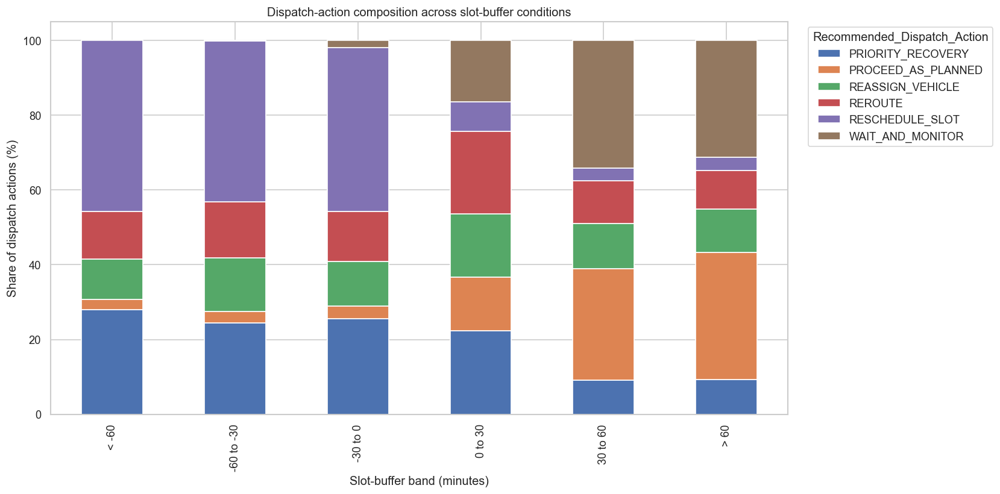

In [32]:
# Slot-buffer bins and dispatch-action composition
df_tmp = df.copy()
df_tmp["Slot_Buffer_Band"] = pd.cut(
    df_tmp["Slot_Buffer_min"],
    bins=[-np.inf, -60, -30, 0, 30, 60, np.inf],
    labels=["< -60", "-60 to -30", "-30 to 0", "0 to 30", "30 to 60", "> 60"]
)

slot_ct = pd.crosstab(
    df_tmp["Slot_Buffer_Band"], df_tmp[TARGET], normalize="index"
) * 100

slot_ct.plot(kind="bar", stacked=True, figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Slot-buffer band (minutes)")
plt.title("Dispatch-action composition across slot-buffer conditions")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("18_slot_buffer_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/19_terminal_congestion_action_composition.png


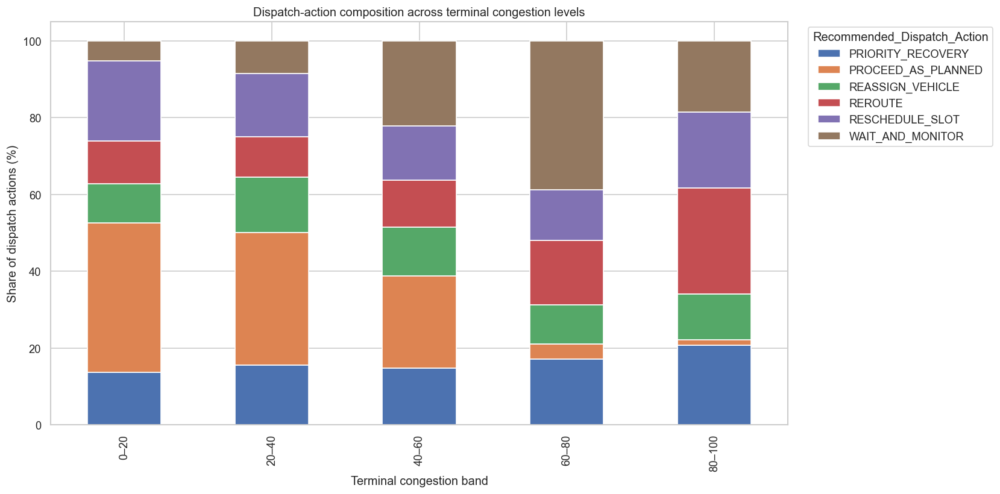

In [33]:
# Congestion bins and action composition
df_tmp["Terminal_Congestion_Band"] = pd.cut(
    df_tmp["Terminal_Congestion_Index"],
    bins=[-np.inf, 20, 40, 60, 80, np.inf],
    labels=["0–20", "20–40", "40–60", "60–80", "80–100"]
)

cong_ct = pd.crosstab(
    df_tmp["Terminal_Congestion_Band"], df_tmp[TARGET], normalize="index"
) * 100

cong_ct.plot(kind="bar", stacked=True, figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Terminal congestion band")
plt.title("Dispatch-action composition across terminal congestion levels")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("19_terminal_congestion_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/20_current_delay_action_composition.png


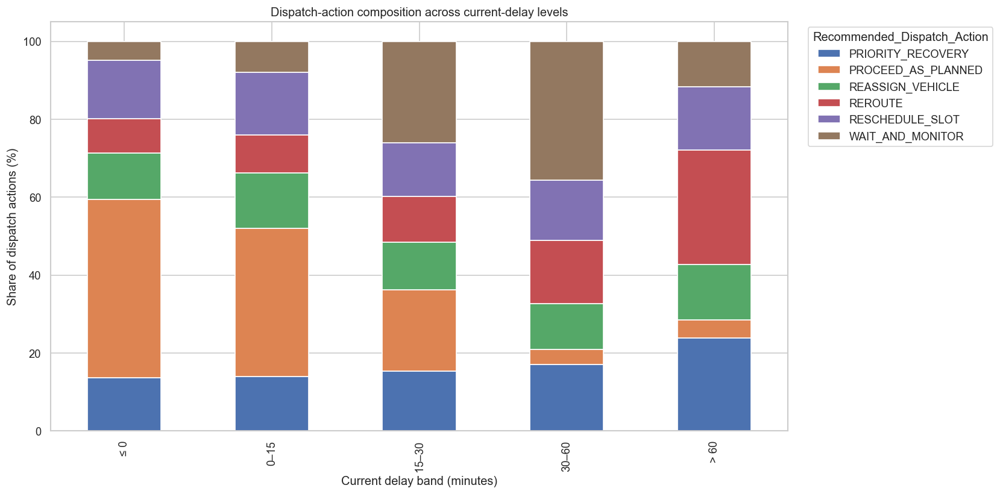

In [34]:
# Delay bins and action composition
df_tmp["Delay_Band"] = pd.cut(
    df_tmp["Current_Delay_min"],
    bins=[-np.inf, 0, 15, 30, 60, np.inf],
    labels=["≤ 0", "0–15", "15–30", "30–60", "> 60"]
)

delay_ct = pd.crosstab(
    df_tmp["Delay_Band"], df_tmp[TARGET], normalize="index"
) * 100

delay_ct.plot(kind="bar", stacked=True, figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Current delay band (minutes)")
plt.title("Dispatch-action composition across current-delay levels")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("20_current_delay_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/21_vehicle_technical_status_action_composition.png


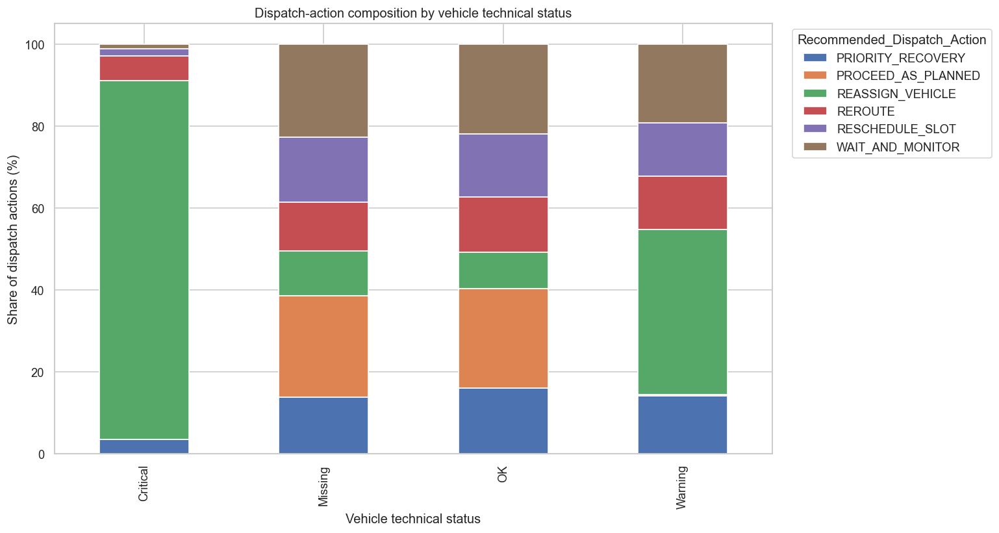

In [35]:
# Technical status vs action
tech_ct = pd.crosstab(
    df["Vehicle_Technical_Status"].fillna("Missing"),
    df[TARGET],
    normalize="index"
) * 100

tech_ct.plot(kind="bar", stacked=True, figsize=(13, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Vehicle technical status")
plt.title("Dispatch-action composition by vehicle technical status")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("21_vehicle_technical_status_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/22_alternative_route_action_composition.png


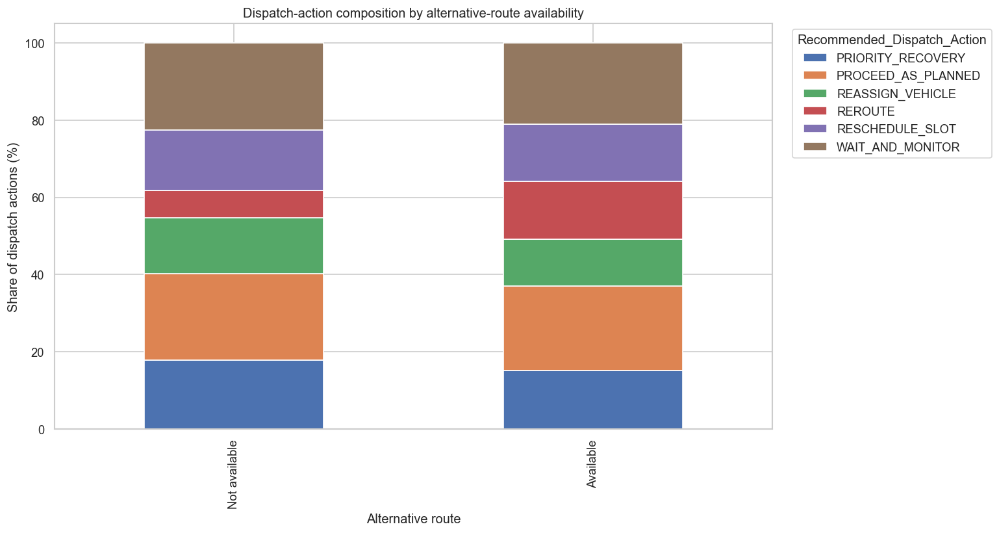

In [36]:
# Alternative-route availability vs action
route_ct = pd.crosstab(
    df["Alternative_Route_Available"].fillna(False),
    df[TARGET],
    normalize="index"
) * 100

route_ct.index = route_ct.index.map({True: "Available", False: "Not available"})
route_ct.plot(kind="bar", stacked=True, figsize=(13, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Alternative route")
plt.title("Dispatch-action composition by alternative-route availability")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("22_alternative_route_action_composition")


## 10. Temporal analysis

`Event_Timestamp` can be transformed into calendar features. The dataset is examined by month and hour to identify possible operational patterns. These are exploratory patterns only; they should not be interpreted as causal effects.

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/23_monthly_case_volume.png


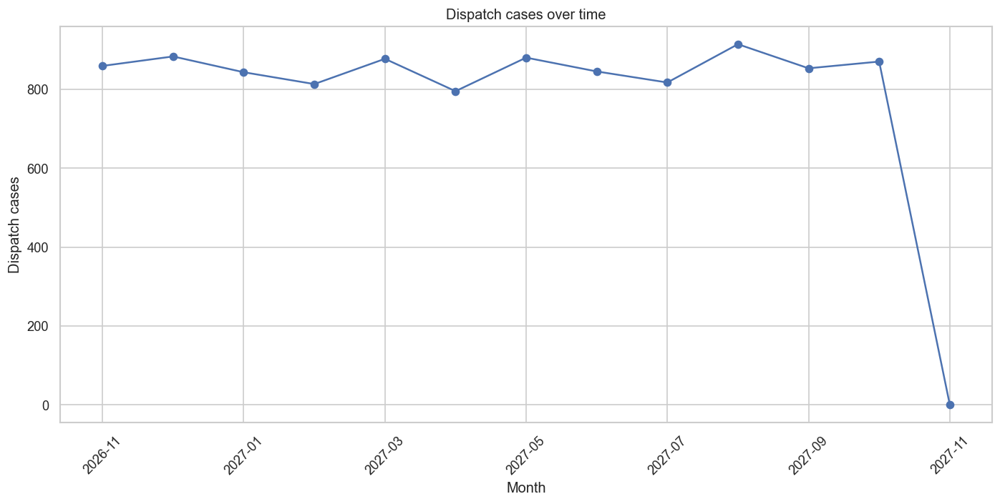

In [37]:
df_time = df.copy()
df_time["Event_Timestamp"] = pd.to_datetime(df_time["Event_Timestamp"], errors="coerce")
df_time["Month"] = df_time["Event_Timestamp"].dt.to_period("M").astype(str)
df_time["Hour"] = df_time["Event_Timestamp"].dt.hour

monthly_counts = df_time.groupby("Month").size()
plt.figure(figsize=(14, 6))
monthly_counts.plot(marker="o")
plt.xlabel("Month")
plt.ylabel("Dispatch cases")
plt.title("Dispatch cases over time")
plt.xticks(rotation=45)
show_and_save("23_monthly_case_volume")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/24_monthly_action_mix.png


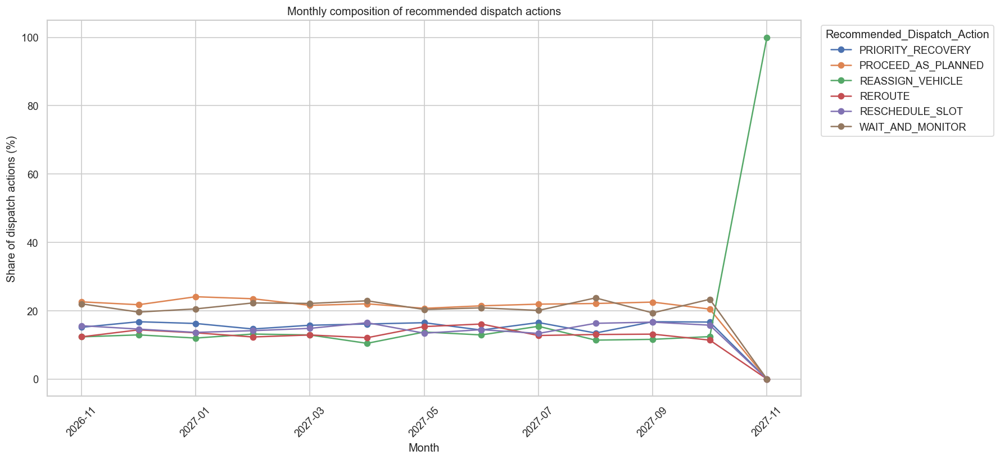

In [38]:
monthly_action = pd.crosstab(
    df_time["Month"], df_time[TARGET], normalize="index"
) * 100

monthly_action.plot(kind="line", marker="o", figsize=(15, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Month")
plt.title("Monthly composition of recommended dispatch actions")
plt.xticks(rotation=45)
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("24_monthly_action_mix")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2/25_hourly_action_mix.png


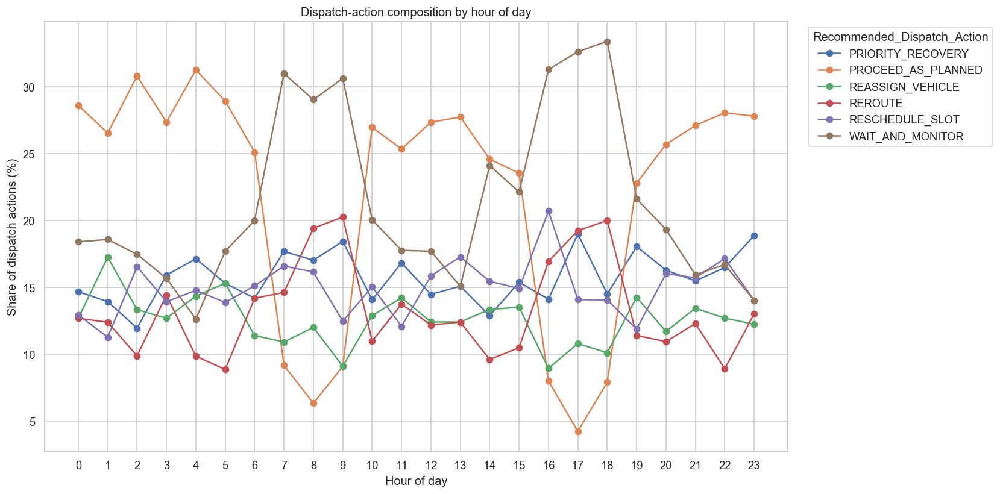

In [39]:
hourly_action = pd.crosstab(
    df_time["Hour"], df_time[TARGET], normalize="index"
) * 100

hourly_action.plot(kind="line", marker="o", figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Hour of day")
plt.title("Dispatch-action composition by hour of day")
plt.xticks(range(0, 24))
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("25_hourly_action_mix")


## 11. Brainstorming: findings, hypotheses, and questions

The brainstorming section translates the EDA into operationally testable ideas. Each statement is linked to a specific table or figure generated above. These are **hypotheses for later investigation**, not claims of causality.

In [40]:
# Automated evidence table for brainstorming
brainstorm_evidence = []

# Class distribution
largest_class = target_counts.idxmax()
smallest_class = target_counts.idxmin()
brainstorm_evidence.append({
    "Evidence": "Target distribution",
    "Observed result": f"{largest_class} is the largest class ({target_counts[largest_class]:,}; {target_pct[largest_class]:.2f}%), while {smallest_class} is the smallest ({target_counts[smallest_class]:,}; {target_pct[smallest_class]:.2f}%).",
    "Reference": "Figure 3 / Figure 4 and target_table"
})

# Missingness
highest_missing_feature = missing_pct.index[0]
brainstorm_evidence.append({
    "Evidence": "Missingness",
    "Observed result": f"{highest_missing_feature} has the highest missing-value rate at {missing_pct.iloc[0]:.2f}%.",
    "Reference": "Figure 1 / Figure 2 and missing_table"
})

# Strongest correlations
strongest = corr_pairs.sort_values("abs_r", ascending=False).iloc[0]
brainstorm_evidence.append({
    "Evidence": "Numeric association",
    "Observed result": f"The strongest absolute Pearson correlation among numeric variables is between {strongest['feature_1']} and {strongest['feature_2']} (r={strongest['pearson_r']:.3f}).",
    "Reference": "Figure 13 and corr_pairs"
})

display(pd.DataFrame(brainstorm_evidence))


,Evidence,Observed result,Reference
0,Target distribution,"PROCEED_AS_PLANNED is the largest class (2,258...",Figure 3 / Figure 4 and target_table
1,Missingness,Alternative_Route_Extra_km has the highest mis...,Figure 1 / Figure 2 and missing_table
2,Numeric association,The strongest absolute Pearson correlation amo...,Figure 13 and corr_pairs


### Brainstorming points

**1. Dispatch actions appear to form a multi-regime operational problem.**  
The target distribution contains six distinct operational actions rather than a binary decision. This means later classification analysis should investigate whether each class occupies a distinct operational region or whether several classes overlap substantially.  
**Evidence:** target distribution in Figures 3–4 and class-conditional distributions in Figures 10, 17–22.

**2. Slot-buffer conditions are a direct candidate for action differentiation.**  
A negative `Slot_Buffer_min` represents an expected slot miss according to the project definition. Therefore, the action mix across the slot-buffer bands is an important operational diagnostic.  
**Evidence:** Figure 18.  
**Hypothesis:** As slot buffer moves from positive slack toward negative values, recovery-oriented or rescheduling actions may become more prevalent. This must be tested quantitatively rather than assumed.

**3. Congestion should be investigated jointly rather than as a single variable.**  
The project figure explicitly highlights terminal congestion and route conditions. The dataset separately records `Terminal_Congestion_Index` and `Road_Congestion_Index`, allowing the analysis to distinguish terminal-side and corridor-side pressure.  
**Evidence:** Figure 13 correlation heatmap, Figure 16 bubble chart, and Figure 19 terminal-congestion action composition.  
**Question:** Are dispatch actions more strongly differentiated by terminal congestion, road congestion, or their combination?

**4. Delay and ETA uncertainty may provide complementary information.**  
`Current_Delay_min` measures accumulated delay, whereas `ETA_Uncertainty_min` represents uncertainty around the ETA. A dispatch case can therefore have high delay but relatively stable ETA, or lower current delay but substantial uncertainty.  
**Evidence:** Figures 10, 14, 17, and 20.  
**Hypothesis:** The combination of delay and ETA uncertainty may separate monitoring decisions from recovery decisions more clearly than either feature alone.

**5. Vehicle technical status is a natural candidate for vehicle reassignment analysis.**  
The scenario explicitly states that a vehicle can develop a technical warning. The dataset contains `Vehicle_Technical_Status` with operational states such as OK, Warning, and Critical.  
**Evidence:** Figure 21.  
**Question:** Does the action distribution change materially between OK, Warning, and Critical states, and is `REASSIGN_VEHICLE` concentrated in specific states?

**6. Alternative resources create a potentially important decision constraint.**  
The dataset records alternative slots, terminals, routes, compatible vehicles, and driver changes. These variables represent whether the dispatcher has feasible recovery options.  
**Evidence:** Figures 22 and the categorical/boolean analyses.  
**Hypothesis:** The availability of alternatives may distinguish feasible recovery actions from cases that must remain as planned or wait for further information.

**7. Commercial exposure may change the operational priority of a case.**  
`Service_Level_Penalty_EUR` represents synthetic financial exposure if the service commitment is missed. It is therefore relevant to investigate whether high-exposure cases have a different action mix.  
**Evidence:** Figures 10, 14, 16, and 17.  
**Question:** Do high-penalty cases show a greater prevalence of proactive recovery actions after controlling for congestion and delay?

**8. Outliers should be interpreted as potential operational events, not automatically removed.**  
The IQR analysis identifies observations that are unusual relative to the bulk of the sample. In a logistics control-tower setting, extreme congestion, delay, disruption duration, or negative slot buffers may represent meaningful disruption scenarios.  
**Evidence:** Figures 9–12.  
**Methodological support:** NIST recommends investigating unusual observations rather than automatically deleting them.

**9. Temporal patterns may reveal operating regimes.**  
The dataset contains timestamps, shifts, and day-of-week information. Monthly and hourly action-mix plots can reveal whether the synthetic dispatch environment has temporal variation.  
**Evidence:** Figures 23–25.  
**Question:** Are certain dispatch actions concentrated in particular hours or months, and do those differences remain after considering congestion and disruption variables?

**10. Data quality itself should be part of the modeling discussion.**  
The supplied file contains 10,250 rows while the project description states 10,000 cases, and several variables contain missing values. This discrepancy should be documented in the report rather than silently corrected.  
**Evidence:** Section 2 structural checks and missingness tables.  
**Question:** Is the additional 250-row difference intentional in the supplied dataset, or should the group clarify it with the instructor before final modeling?


## 12. EDA conclusion

The dataset provides a rich six-class dispatch-decision problem combining congestion, disruption, time-window risk, resource constraints, alternative options, commercial exposure, and vehicle/terminal state.

The EDA identifies several operational dimensions that warrant deeper analysis in the later classification stage:

1. **Congestion:** terminal and road congestion should be analyzed jointly.
2. **Time-window risk:** slot buffer, current delay, and ETA uncertainty are central temporal variables.
3. **Resource constraints:** remaining driver hours, compatible vehicles, and driver-change availability may affect feasible actions.
4. **Vehicle condition:** technical status provides a direct operational signal for reassignment decisions.
5. **Alternative options:** alternative route/terminal/slot availability may distinguish recovery strategies.
6. **Commercial exposure:** service-level penalty can be examined as a prioritization signal.
7. **Data quality:** missingness and the observed 10,250-row dataset size require explicit documentation.

No observations are deleted in this EDA. Any imputation, encoding, feature selection, class-balancing strategy, and classifier selection should be justified separately during the subsequent modeling phase.


## 13. External methodological references

The notebook uses the following external methodological sources to support the EDA approach:

1. **NIST/SEMATECH e-Handbook of Statistical Methods — Exploratory Data Analysis.** NIST describes EDA as an approach for gaining insight, uncovering structure, detecting outliers/anomalies, and using graphical techniques to explore data.
2. **NIST/SEMATECH — Detection of Outliers.** Supports investigating unusual observations rather than automatically treating every outlier as erroneous.
3. **scikit-learn documentation — Imputation of Missing Values.** Provides background on why missing values require explicit preprocessing before many machine-learning estimators.
4. **pandas documentation.** Used as the implementation reference for tabular data handling and missing-value/statistical summaries.

These references support the methodology; the substantive observations in this notebook are derived from the supplied dataset.


### References

- NIST/SEMATECH. *What is Exploratory Data Analysis?* https://www.itl.nist.gov/div898/handbook/eda/section1/eda11.htm
- NIST/SEMATECH. *Exploratory Data Analysis — Detailed Table of Contents.* https://www.itl.nist.gov/div898/handbook/eda/eda_d.htm
- NIST/SEMATECH. *Detection of Outliers.* https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
- NIST/SEMATECH. *The Role of Graphics.* https://www.itl.nist.gov/div898/handbook/eda/section1/eda15.htm
- scikit-learn. *Imputation of Missing Values.* https://scikit-learn.org/stable/modules/impute.html
- pandas documentation. *User Guide.* https://pandas.pydata.org/docs/user_guide/
